# **Dataset Preparation**


In [1]:
import os, glob, random
import numpy as np, pandas as pd
SEED = 42; random.seed(SEED); np.random.seed(SEED)
ROOT = glob.glob("/kaggle/input/**/MERGE_Bimodal_Complete", recursive=True)[0]
AUDIO, LYR, TVT = (os.path.join(ROOT, x) for x in ("audio", "lyrics", "tvt_dataframes"))
OUT = "/kaggle/working/p0"; os.makedirs(OUT, exist_ok=True)
print(ROOT)

/kaggle/input/datasets/namitabhatta/merge-bimodal-complete/MERGE_Bimodal_Complete


In [2]:
def inventory(mod_dir):
    rows = []
    for q in sorted(os.listdir(mod_dir)):
        for fn in sorted(os.listdir(os.path.join(mod_dir, q))):
            stem, ext = os.path.splitext(fn)
            rows.append(dict(quadrant=q, stem=stem, ext=ext.lower(),
                             path=os.path.join(mod_dir, q, fn)))
    return pd.DataFrame(rows)

aud, lyr = inventory(AUDIO), inventory(LYR)
for name, df in [("audio", aud), ("lyrics", lyr)]:
    print(f"{name}: {len(df)} files | ext {df.ext.value_counts().to_dict()}")
    print("  per quadrant:", df.quadrant.value_counts().sort_index().to_dict())
    print("  duplicate stems:", df.stem.duplicated().sum(), "| sample:", df.stem.head(3).tolist())

audio: 2216 files | ext {'.mp3': 2216}
  per quadrant: {'Q1': 525, 'Q2': 673, 'Q3': 500, 'Q4': 518}
  duplicate stems: 0 | sample: ['A005', 'A011', 'A014']
lyrics: 2216 files | ext {'.txt': 2216}
  per quadrant: {'Q1': 525, 'Q2': 673, 'Q3': 500, 'Q4': 518}
  duplicate stems: 0 | sample: ['L004-120', 'L005-84', 'L018-109']


In [3]:
m = aud.merge(lyr, on="stem", how="outer", suffixes=("_a", "_l"), indicator=True)
print(m["_merge"].value_counts().to_dict())
both = m[m["_merge"] == "both"]
print("quadrant folder mismatch:", (both.quadrant_a != both.quadrant_l).sum())
print(m[m["_merge"] != "both"][["stem", "quadrant_a", "quadrant_l"]].head(10))

{'both': 2083, 'left_only': 133, 'right_only': 133}
quadrant folder mismatch: 0
   stem quadrant_a quadrant_l
0  A001         Q4        NaN
1  A002         Q4        NaN
2  A003         Q3        NaN
3  A004         Q3        NaN
4  A005         Q1        NaN
5  A010         Q2        NaN
6  A011         Q1        NaN
7  A013         Q2        NaN
8  A014         Q1        NaN
9  A017         Q4        NaN


In [4]:
for p in sorted(glob.glob(os.path.join(ROOT, "**", "*.csv"), recursive=True)):
    df = pd.read_csv(p)
    print(f"\n== {os.path.relpath(p, ROOT)} | shape {df.shape}")
    print(df.columns.tolist())
    print(df.head(2).to_string())


== merge_bimodal_complete_av_values.csv | shape (2216, 4)
['Audio_Song', 'Lyric_Song', 'Arousal', 'Valence']
  Audio_Song Lyric_Song  Arousal  Valence
0       A001       L051  0.29375  0.89375
1       A002       L052  0.33750  0.68125

== merge_bimodal_complete_metadata.csv | shape (2216, 27)
['Audio_Song', 'Lyric_Song', 'Quadrant', 'AllMusic Id', 'AllMusic Extraction Date', 'Artist', 'Title', 'Relevance', 'Year', 'LowestYear', 'Duration', 'Moods', 'MoodsAll', 'MoodsAllWeights', 'Genres', 'GenreWeights', 'Themes', 'ThemeWeights', 'Styles', 'StyleWeights', 'AppearancesTrackIDs', 'AppearancesAlbumIDs', 'Sample', 'SampleURL', 'ActualYear', 'num_Genres', 'num_MoodsAll']
  Audio_Song Lyric_Song Quadrant   AllMusic Id AllMusic Extraction Date           Artist                   Title  Relevance        Year LowestYear  Duration                                                                 Moods                                                                                                  

In [5]:
import soundfile as sf, librosa
def ainfo(p):
    try:
        i = sf.info(p); return i.samplerate, i.channels, i.duration, "sf"
    except Exception:
        y, sr = librosa.load(p, sr=None, mono=False)
        return sr, (1 if y.ndim == 1 else y.shape[0]), y.shape[-1] / sr, "librosa"

info = pd.DataFrame([ainfo(p) for p in aud.path], columns=["sr", "ch", "dur", "reader"])
aud = pd.concat([aud.reset_index(drop=True), info], axis=1)
print("sr:", aud.sr.value_counts().to_dict(), "| ch:", aud.ch.value_counts().to_dict(),
      "| reader:", aud.reader.value_counts().to_dict())
print(aud.dur.describe().round(2).to_string())

sr: {32000: 1571, 22050: 476, 44100: 169} | ch: {2: 2214, 1: 2} | reader: {'sf': 2216}
count    2216.00
mean       29.89
std         0.67
min         4.78
25%        29.95
50%        30.06
75%        30.06
max        30.82


In [6]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("roberta-base"); tok.model_max_length = 10**6

def read_txt(p):
    raw = open(p, "rb").read()
    try: return raw.decode("utf-8"), "utf-8"
    except UnicodeDecodeError: return raw.decode("latin-1"), "latin-1"

recs = []
for p in lyr.path:
    t, enc = read_txt(p); lines = [l for l in t.splitlines() if l.strip()]
    recs.append(dict(enc=enc, n_lines=len(lines), n_words=len(t.split()),
                     n_tok=len(tok(t, add_special_tokens=False)["input_ids"]),
                     n_stanza_breaks=t.count("\n\n"),
                     n_bracket_lines=sum(l.strip().startswith(("[", "(")) for l in lines),
                     nonascii=sum(ord(c) > 127 for c in t) / max(len(t), 1)))
lyr = pd.concat([lyr.reset_index(drop=True), pd.DataFrame(recs)], axis=1)
print("encoding:", lyr.enc.value_counts().to_dict(), "| empty:", (lyr.n_words == 0).sum())
print(lyr[["n_lines","n_words","n_tok","n_stanza_breaks","n_bracket_lines","nonascii"]]
      .describe().round(2).to_string())
print("share > 510 tokens:", round((lyr.n_tok > 510).mean(), 3))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

encoding: {'utf-8': 2216} | empty: 0
       n_lines  n_words    n_tok  n_stanza_breaks  n_bracket_lines  nonascii
count  2216.00  2216.00  2216.00          2216.00          2216.00   2216.00
mean     37.38   247.46   353.56             5.61             0.75      0.00
std      22.29   167.62   249.98             3.37             3.02      0.00
min       3.00    12.00    21.00             0.00             0.00      0.00
25%      22.00   139.00   192.00             3.00             0.00      0.00
50%      32.00   198.00   275.50             5.00             0.00      0.00
75%      46.25   289.00   409.25             7.00             0.00      0.00
max     177.00  1031.00  1562.00            29.00            48.00      0.02
share > 510 tokens: 0.172


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
norm = lyr.path.map(lambda p: " ".join(read_txt(p)[0].lower().split()))
print("exact-duplicate lyrics files:", norm.duplicated(keep=False).sum())
X = TfidfVectorizer(min_df=2).fit_transform(norm)
S = (X @ X.T).toarray(); np.fill_diagonal(S, 0)
i, j = np.where(np.triu(S) > 0.9)
print("near-duplicate pairs (cos > 0.9):", len(i))
print(pd.DataFrame({"a": lyr.stem.values[i], "b": lyr.stem.values[j],
                    "cos": S[i, j].round(3)}).head(10))

exact-duplicate lyrics files: 26
near-duplicate pairs (cos > 0.9): 76
              a             b    cos
0      L004-120  MT0011933875  0.907
1      L036-118  MT0002672499  1.000
2          L055  MT0004444570  1.000
3      L155-117  MT0002343207  1.000
4  MT0000128573  MT0003603497  0.985
5  MT0000146966  MT0001521543  0.990
6  MT0002177145  MT0010100285  0.901
7  MT0002294387  MT0002366291  0.973
8  MT0002294387  MT0004692456  1.000
9  MT0002366291  MT0004692456  0.973


In [8]:
for p in lyr.sample(2, random_state=SEED).path:
    print(f"\n----- {os.path.basename(p)} -----")
    print("\n".join(read_txt(p)[0].splitlines()[:15]))
aud.to_csv(f"{OUT}/audio_inventory.csv", index=False)
lyr.drop(columns=[]).to_csv(f"{OUT}/lyrics_inventory.csv", index=False)


----- MT0009041370.txt -----
When the screen turns, it's too late
No one's to burn but yourself
I want to buy everything you got
No hope now for a TV junk

24 hour bullshit
24 hour bullshit

I want out, don't want your help
Spend my time trying to distance myself
Fall in line, now follow suit
It's my God and my religion

24 hour bullshit
24 hour bullshit

----- MT0005523766.txt -----
I know a cat named Way Out Willie
He's got a cool little chick named Rockin' Millie
He can walk and stroll and Susie Q
And do that crazy hand jive too

Papa told Willie, you'll ruin my home
You and that hand jive have got to go
Willie said, Papa, don't put me down
They're doin' the hand jive all over town

Hand jive, hand jive, hand jive, doin' that crazy hand jive

Mama, Mama look at Uncle Joe
He's doin' that hand jive with sister Flo
Grandma gave baby sister a dime


In [9]:
meta = pd.read_csv(f"{ROOT}/merge_bimodal_complete_metadata.csv")
lyr["key"] = lyr.stem.str.split("-").str[0]
apath, aq = dict(zip(aud.stem, aud.path)), dict(zip(aud.stem, aud.quadrant))
lpath = {**dict(zip(lyr.key, lyr.path)), **dict(zip(lyr.stem, lyr.path))}
lq    = {**dict(zip(lyr.key, lyr.quadrant)), **dict(zip(lyr.stem, lyr.quadrant))}

pairs = meta[["Audio_Song", "Lyric_Song", "Quadrant", "Artist", "Title", "Duration"]].copy()
pairs["audio_path"], pairs["lyrics_path"] = pairs.Audio_Song.map(apath), pairs.Lyric_Song.map(lpath)
print("lyrics key unique:", lyr.key.is_unique)
print("missing audio:", pairs.audio_path.isna().sum(), "| missing lyrics:", pairs.lyrics_path.isna().sum())
print("unique Audio_Song / Lyric_Song:", pairs.Audio_Song.is_unique, pairs.Lyric_Song.is_unique)
print("label != audio folder:", (pairs.Quadrant != pairs.Audio_Song.map(aq)).sum(),
      "| label != lyrics folder:", (pairs.Quadrant != pairs.Lyric_Song.map(lq)).sum())
print("legacy lyric stems:", lyr[lyr.stem.str.contains("-")].stem.head(5).tolist())

lyrics key unique: True
missing audio: 0 | missing lyrics: 0
unique Audio_Song / Lyric_Song: True True
label != audio folder: 0 | label != lyrics folder: 0
legacy lyric stems: ['L004-120', 'L005-84', 'L018-109', 'L022-121', 'L036-118']


In [10]:
def load_split(tag):
    return {s: pd.read_csv(f"{TVT}/tvt_{tag}/tvt_{tag}_{s}_bimodal_complete.csv")
            for s in ("train", "validate", "test")}

qmap = dict(zip(pairs.Audio_Song, pairs.Quadrant))
for tag in ("70_15_15", "40_30_30"):
    sp = load_split(tag); ids = {k: set(v.Song) for k, v in sp.items()}
    allids = set().union(*ids.values())
    print(f"\n[{tag}] sizes", {k: len(v) for k, v in sp.items()}, "| union", len(allids),
          "| dups within", {k: int(v.Song.duplicated().sum()) for k, v in sp.items()})
    print("  overlap tr∩va / tr∩te / va∩te:", len(ids["train"] & ids["validate"]),
          len(ids["train"] & ids["test"]), len(ids["validate"] & ids["test"]))
    print("  IDs not in metadata Audio_Song:", len(allids - set(pairs.Audio_Song)))
    for k, v in sp.items():
        print(f"  {k}: label mismatch {(v.Quadrant != v.Song.map(qmap)).sum()} |",
              v.Quadrant.value_counts().sort_index().to_dict())


[70_15_15] sizes {'train': 1552, 'validate': 332, 'test': 332} | union 2216 | dups within {'train': 0, 'validate': 0, 'test': 0}
  overlap tr∩va / tr∩te / va∩te: 0 0 0
  IDs not in metadata Audio_Song: 0
  train: label mismatch 0 | {'Q1': 365, 'Q2': 477, 'Q3': 346, 'Q4': 364}
  validate: label mismatch 0 | {'Q1': 80, 'Q2': 98, 'Q3': 77, 'Q4': 77}
  test: label mismatch 0 | {'Q1': 80, 'Q2': 98, 'Q3': 77, 'Q4': 77}

[40_30_30] sizes {'train': 888, 'validate': 664, 'test': 664} | union 2216 | dups within {'train': 0, 'validate': 0, 'test': 0}
  overlap tr∩va / tr∩te / va∩te: 0 0 0
  IDs not in metadata Audio_Song: 0
  train: label mismatch 0 | {'Q1': 207, 'Q2': 275, 'Q3': 194, 'Q4': 212}
  validate: label mismatch 0 | {'Q1': 159, 'Q2': 199, 'Q3': 153, 'Q4': 153}
  test: label mismatch 0 | {'Q1': 159, 'Q2': 199, 'Q3': 153, 'Q4': 153}


In [11]:
sp = load_split("70_15_15")
pairs["split"] = pairs.Audio_Song.map({s: k for k, v in sp.items() for s in v.Song})
pairs["Artist"] = pairs.Artist.fillna("").str.strip()
print("split counts:", pairs.split.value_counts(dropna=False).to_dict())

n_split = pairs.groupby("Artist").split.nunique()
print("artists:", pairs.Artist.nunique(), "| spanning >1 split:", (n_split > 1).sum())
train_artists = set(pairs[pairs.split == "train"].Artist)
for s in ("validate", "test"):
    print(f"  {s}: share of songs whose artist is in train =",
          round(pairs[pairs.split == s].Artist.isin(train_artists).mean(), 3))
k = pairs.Artist.str.lower() + "|" + pairs.Title.fillna("").str.lower().str.strip()
print("duplicate artist+title rows:", k.duplicated(keep=False).sum())

split counts: {'train': 1552, 'validate': 332, 'test': 332}
artists: 1137 | spanning >1 split: 240
  validate: share of songs whose artist is in train = 0.545
  test: share of songs whose artist is in train = 0.599
duplicate artist+title rows: 12


In [12]:
short = aud[aud.dur < 25].merge(pairs[["Audio_Song", "split"]], left_on="stem", right_on="Audio_Song")
print("clips < 25 s:", len(short)); print(short[["stem", "quadrant", "dur", "sr", "ch", "split"]])
cov = (30 / pairs.Duration).clip(upper=1)
print("full-track duration (s):", pairs.Duration.describe().round(1).to_dict())
print("excerpt covers ~", round(cov.median(), 3), "of the full track (median); missing Duration:",
      pairs.Duration.isna().sum())

clips < 25 s: 1
           stem quadrant       dur     sr  ch  split
0  MT0002054074       Q4  4.778656  32000   2  train
full-track duration (s): {'count': 2076.0, 'mean': 211.6, 'std': 96.7, 'min': 0.0, '25%': 165.0, '50%': 212.0, '75%': 261.0, 'max': 1359.0}
excerpt covers ~ 0.142 of the full track (median); missing Duration: 140


In [13]:
pairs.to_csv(f"{OUT}/pairs_70_15_15.csv", index=False)
print(pairs.shape, pairs.isna().sum()[["audio_path", "lyrics_path", "split"]].to_dict())

(2216, 9) {'audio_path': 0, 'lyrics_path': 0, 'split': 0}


In [14]:
pairs["k"] = k
d = pairs[pairs.k.duplicated(keep=False)].sort_values("k")
print(d[["Audio_Song", "Lyric_Song", "Quadrant", "Artist", "Title", "split"]].to_string())
g = d.groupby("k")
print("groups:", g.ngroups, "| spanning >1 split:", (g.split.nunique() > 1).sum(),
      "| conflicting labels:", (g.Quadrant.nunique() > 1).sum())

        Audio_Song    Lyric_Song Quadrant           Artist                    Title     split
42        A066-140      L116-140       Q4             Enya    Journey of the Angels     train
1452  MT0009795009  MT0009795009       Q4             Enya    Journey of the Angels  validate
821   MT0003965796  MT0003965796       Q1   Gloria Estefan  Rhythm Is Gonna Get You      test
1196  MT0007132421  MT0007132421       Q1   Gloria Estefan  Rhythm Is Gonna Get You  validate
77        A114-120      L004-120       Q1  Luther Vandross           Never Too Much     train
1653  MT0011933875  MT0011933875       Q1  Luther Vandross           Never Too Much  validate
72        A105-117      L155-117       Q1           Prince                     Kiss     train
595   MT0002343207  MT0002343207       Q1           Prince                     Kiss     train
4             A005          L055       Q1           Prince           U Got the Look     train
874   MT0004444570  MT0004444570       Q1           Prince  

In [15]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
_, comp = connected_components(csr_matrix(np.triu(S) > 0.9), directed=False)
lyr["dup_group"] = comp
L = lyr[["stem", "dup_group"]].join(
    pairs.set_index("Lyric_Song")[["Audio_Song", "split", "Quadrant", "Artist", "Title"]], on="stem")
grp = L[L.groupby("dup_group").stem.transform("size") > 1]
gg = grp.groupby("dup_group")
print("groups:", gg.ngroups, "| songs:", len(grp),
      "| spanning >1 split:", (gg.split.nunique() > 1).sum(),
      "| conflicting quadrants:", (gg.Quadrant.nunique() > 1).sum())
has_train = grp.dup_group.map(gg.split.apply(lambda s: (s == "train").any()))
for s in ("validate", "test"):
    x = grp[(grp.split == s) & has_train]
    print(f"{s}: songs with a lyric twin in train = {len(x)}")
n_test = grp[grp.split == "test"].groupby("dup_group").size()
print("test songs sharing lyrics with another test song:", int(n_test[n_test > 1].sum()))
print(grp.sort_values("dup_group")[["stem", "dup_group", "split", "Quadrant", "Artist", "Title"]]
      .head(30).to_string())
L[["stem", "Audio_Song", "dup_group"]].to_csv(f"{OUT}/lyric_dup_groups.csv", index=False)

groups: 58 | songs: 126 | spanning >1 split: 31 | conflicting quadrants: 5
validate: songs with a lyric twin in train = 15
test: songs with a lyric twin in train = 13
test songs sharing lyrics with another test song: 4
              stem  dup_group     split Quadrant                          Artist                                         Title
0         L004-120          0     train       Q1                 Luther Vandross                                Never Too Much
379   MT0011933875          0  validate       Q1                 Luther Vandross                                Never Too Much
138   MT0002672499          4     train       Q1              The Isley Brothers                               Twist and Shout
4         L036-118          4     train       Q1                     The Beatles                               Twist and Shout
194   MT0004444570          9     train       Q1                          Prince                                U Got the Look
9             L055 

In [16]:
pairs = pairs.drop(columns=["dup_group"], errors="ignore").merge(
    L[["stem", "dup_group"]].rename(columns={"stem": "Lyric_Song"}), on="Lyric_Song", how="left")
pairs["lyric_dup"] = pairs.groupby("dup_group").Audio_Song.transform("size") > 1
train_groups = set(pairs.loc[pairs.split == "train", "dup_group"])
pairs["twin_in_train"] = pairs.lyric_dup & (pairs.split != "train") & pairs.dup_group.isin(train_groups)
pairs.drop(columns=["k"], errors="ignore").to_csv(f"{OUT}/pairs_70_15_15.csv", index=False)
print(pairs.groupby("split")[["lyric_dup", "twin_in_train"]].sum())

          lyric_dup  twin_in_train
split                             
test             21             13
train            86              0
validate         19             15


# **Pretrained Feature Extraction**

In [17]:
import os, time, inspect, numpy as np, pandas as pd, torch, librosa, transformers
import torch.nn.functional as F
from tqdm.auto import tqdm
DEV = "cuda"; torch.manual_seed(42)
FEAT = "/kaggle/working/features"; os.makedirs(FEAT, exist_ok=True)
pairs = pd.read_csv("/kaggle/working/p0/pairs_70_15_15.csv")
print("transformers", transformers.__version__, "|", pairs.shape, "| GPU:", torch.cuda.is_available())

transformers 5.16.1 | (2216, 12) | GPU: True


In [18]:
from transformers import AutoModel, AutoTokenizer, Wav2Vec2FeatureExtractor
mert = AutoModel.from_pretrained("m-a-p/MERT-v1-95M", trust_remote_code=True).to(DEV).eval()
proc = Wav2Vec2FeatureExtractor.from_pretrained("m-a-p/MERT-v1-95M", trust_remote_code=True)
tok  = AutoTokenizer.from_pretrained("roberta-base")
rob  = AutoModel.from_pretrained("roberta-base").to(DEV).eval()
for m in (mert, rob):
    for p in m.parameters(): p.requires_grad_(False)
print("MERT layers:", mert.config.num_hidden_layers, "| RoBERTa layers:", rob.config.num_hidden_layers)

config.json:   0%|          | 0.00/1.82k [00:00<?, ?B/s]

configuration_MERT.py:   0%|          | 0.00/5.34k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/m-a-p/MERT-v1-95M:
- configuration_MERT.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_MERT.py:   0%|          | 0.00/18.0k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/m-a-p/MERT-v1-95M:
- modeling_MERT.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


MERT layers: 12 | RoBERTa layers: 12


In [19]:
def make_capture(first_module, layers):
    cap = {}
    def save(i):
        def hook(mod, inp, out): cap[i] = out[0] if isinstance(out, tuple) else out
        return hook
    handles = [first_module.register_forward_hook(save(0))] + \
              [l.register_forward_hook(save(i + 1)) for i, l in enumerate(layers)]
    return cap, handles

for h in globals().get("_handles", []): h.remove()
mert_cap, h1 = make_capture(mert.encoder.layer_norm, mert.encoder.layers)
rob_cap,  h2 = make_capture(rob.embeddings, rob.encoder.layer)
_handles = h1 + h2

def collect(cap, last):
    hs = [cap[i].float() for i in range(13)]
    assert torch.allclose(hs[-1], last.float(), atol=1e-3), "hook != last_hidden_state"
    return torch.stack(hs, 1)                                  # [B, 13, T, 768]

MERT Functions

In [20]:
SR, CHUNK, RATE = 24000, 5 * 24000, 2

@torch.no_grad()
def mert_forward(chunks, fp16=True):
    x = proc(chunks, sampling_rate=SR, return_tensors="pt").input_values.to(DEV)
    mert_cap.clear()
    with torch.autocast("cuda", dtype=torch.float16, enabled=fp16):
        o = mert(x)
    return collect(mert_cap, o.last_hidden_state)

def mert_feats(path, fp16=True):
    y, _ = librosa.load(path, sr=SR, mono=True)
    chunks = [y[i:i + CHUNK] for i in range(0, len(y), CHUNK)]
    chunks = [c for c in chunks if len(c) >= SR // 2] or [y]
    out = []
    for group in ([c for c in chunks if len(c) == CHUNK], [c for c in chunks if len(c) != CHUNK]):
        if not group: continue
        h = mert_forward(group, fp16)
        for b, c in enumerate(group):
            n = max(1, round(len(c) / SR * RATE))
            out.append(F.adaptive_avg_pool1d(h[b].transpose(1, 2), n).transpose(1, 2))
    return torch.cat(out, 1)                                   # [13, steps, 768]

print("hook version active:", "mert_cap" in inspect.getsource(mert_forward))

hook version active: True


In [21]:
for sid in ["A001", "MT0002054074"]:
    p = pairs.loc[pairs.Audio_Song == sid, "audio_path"].item()
    a16, a32 = mert_feats(p, True), mert_feats(p, False)
    cos = F.cosine_similarity(a16.flatten(1), a32.flatten(1)).min().item()
    print(sid, tuple(a16.shape), "| cosine:", round(cos, 5), "| finite:", torch.isfinite(a16).all().item())

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


A001 (13, 60, 768) | cosine: 1.0 | finite: True
MT0002054074 (13, 10, 768) | cosine: 1.0 | finite: True


In [22]:
REDO_AUDIO = False
AF = f"{FEAT}/audio_mert95_L13.npy"
if REDO_AUDIO or not os.path.exists(AF):
    feats, index, start, t0 = [], [], 0, time.time()
    for sid, p in tqdm(zip(pairs.Audio_Song, pairs.audio_path), total=len(pairs)):
        a = mert_feats(p).half().cpu().numpy().transpose(1, 0, 2)   # [steps, 13, 768]
        feats.append(a); index.append((sid, start, len(a))); start += len(a)
    np.save(AF, np.concatenate(feats)); del feats
    pd.DataFrame(index, columns=["Audio_Song", "start", "length"]).to_csv(f"{FEAT}/audio_index.csv", index=False)
    print(f"{(time.time() - t0) / 60:.1f} min | total steps {start}")
else:
    print("audio features exist:", np.load(AF, mmap_mode="r").shape)

  0%|          | 0/2216 [00:00<?, ?it/s]

16.3 min | total steps 132133


In [23]:
WIN, STRIDE = 510, 255

@torch.no_grad()
def lyric_feats(text):
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    joined = "\n".join(lines)
    enc = tok(joined, add_special_tokens=False, return_offsets_mapping=True, verbose=False)
    ids, offs = enc["input_ids"], enc["offset_mapping"]
    line_of = np.zeros(len(joined), dtype=np.int64); pos = 0
    for i, l in enumerate(lines):
        line_of[pos:pos + len(l) + 1] = i; pos += len(l) + 1
    n = len(ids); H = torch.zeros(13, n, 768, device=DEV); C = torch.zeros(n, device=DEV)
    starts = list(range(0, max(n - WIN, 0) + 1, STRIDE))
    if starts[-1] + WIN < n: starts.append(n - WIN)
    for s in starts:
        w = ids[s:s + WIN]
        x = torch.tensor([[tok.cls_token_id] + w + [tok.sep_token_id]], device=DEV)
        rob_cap.clear()
        with torch.autocast("cuda", dtype=torch.float16):
            o = rob(input_ids=x)
        hs = collect(rob_cap, o.last_hidden_state)[0]          # [13, T, 768]
        H[:, s:s + len(w)] += hs[:, 1:-1]; C[s:s + len(w)] += 1
    H /= C[None, :, None]                                      # FIXED
    keep = [k for k, (a, b) in enumerate(offs) if joined[a:b].strip()]
    li = torch.tensor(line_of[[offs[k][0] for k in keep]], device=DEV)
    out = torch.zeros(13, len(lines), 768, device=DEV).index_add_(1, li, H[:, keep])
    out /= torch.bincount(li, minlength=len(lines)).clamp(min=1)[None, :, None]
    return out.transpose(0, 1)                                 # [lines, 13, 768]

long_i = pairs.lyrics_path.map(lambda p: len(open(p, encoding="utf-8").read())).idxmax()
for i in (0, long_i):
    t = open(pairs.lyrics_path[i], encoding="utf-8").read()
    f = lyric_feats(t)
    print(pairs.Lyric_Song[i], "| tokens:", len(tok(t, add_special_tokens=False)["input_ids"]),
          "| feats:", tuple(f.shape), "| finite:", torch.isfinite(f).all().item())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1369 > 512). Running this sequence through the model will result in indexing errors


L051 | tokens: 147 | feats: (14, 13, 768) | finite: True
MT0028593700 | tokens: 1369 | feats: (143, 13, 768) | finite: True


In [24]:
feats, index, start, t0 = [], [], 0, time.time()
for sid, p in tqdm(zip(pairs.Lyric_Song, pairs.lyrics_path), total=len(pairs)):
    l = lyric_feats(open(p, encoding="utf-8").read()).half().cpu().numpy()
    feats.append(l); index.append((sid, start, len(l))); start += len(l)
np.save(f"{FEAT}/lyrics_roberta_L13.npy", np.concatenate(feats)); del feats
pd.DataFrame(index, columns=["Lyric_Song", "start", "length"]).to_csv(f"{FEAT}/lyrics_index.csv", index=False)
print(f"{(time.time() - t0) / 60:.1f} min | total lines {start}")

  0%|          | 0/2216 [00:00<?, ?it/s]

1.2 min | total lines 82843


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
A, ai = np.load(f"{FEAT}/audio_mert95_L13.npy", mmap_mode="r"), pd.read_csv(f"{FEAT}/audio_index.csv")
L, li = np.load(f"{FEAT}/lyrics_roberta_L13.npy", mmap_mode="r"), pd.read_csv(f"{FEAT}/lyrics_index.csv")
nl = pairs.lyrics_path.map(lambda p: sum(1 for x in open(p, encoding="utf-8").read().splitlines() if x.strip()))
print("audio", A.shape, "| steps min/med/max:", ai.length.min(), ai.length.median(), ai.length.max())
print("lyrics", L.shape, "| lines min/med/max:", li.length.min(), li.length.median(), li.length.max())
print("order ok:", (ai.Audio_Song == pairs.Audio_Song).all(), (li.Lyric_Song == pairs.Lyric_Song).all(),
      "| lines == file lines:", (li.length.values == nl.values).all(),
      "| finite:", np.isfinite(A[::97]).all(), np.isfinite(L[::97]).all())
tr, va = (pairs.split == "train").values, (pairs.split == "validate").values
for name, X, idx in [("audio", A, ai), ("lyrics", L, li)]:
    Z = np.stack([X[s:s + n].astype(np.float32).mean((0, 1)) for s, n in zip(idx.start, idx.length)])
    sc = StandardScaler().fit(Z[tr])
    clf = LogisticRegression(max_iter=3000, C=0.5).fit(sc.transform(Z[tr]), pairs.Quadrant[tr])
    print(f"{name} linear-probe val macro-F1 (sanity only):",
          round(f1_score(pairs.Quadrant[va], clf.predict(sc.transform(Z[va])), average="macro"), 3))

audio (132133, 13, 768) | steps min/med/max: 10 60.0 62
lyrics (82843, 13, 768) | lines min/med/max: 3 32.0 177
order ok: True True | lines == file lines: True | finite: True True
audio linear-probe val macro-F1 (sanity only): 0.693
lyrics linear-probe val macro-F1 (sanity only): 0.704


In [26]:
import os, glob, numpy as np, pandas as pd
D = os.path.dirname(glob.glob("/kaggle/input/**/audio_mert95_L13.npy", recursive=True)[0])
print(D); print({f: os.path.getsize(f"{D}/{f}") for f in sorted(os.listdir(D))})
A = np.load(f"{D}/audio_mert95_L13.npy", mmap_mode="r"); L = np.load(f"{D}/lyrics_roberta_L13.npy", mmap_mode="r")
ai, li = pd.read_csv(f"{D}/audio_index.csv"), pd.read_csv(f"{D}/lyrics_index.csv")
pairs = pd.read_csv(f"{D}/pairs_70_15_15.csv")
print("audio", A.shape, A.dtype, "| lyrics", L.shape, L.dtype, "| pairs", pairs.shape)
print("index ends match arrays:", ai.start.iloc[-1] + ai.length.iloc[-1] == len(A),
      li.start.iloc[-1] + li.length.iloc[-1] == len(L))
print("order ok:", (ai.Audio_Song == pairs.Audio_Song).all(), (li.Lyric_Song == pairs.Lyric_Song).all(),
      "| finite (sampled):", np.isfinite(A[::997]).all(), np.isfinite(L[::997]).all())

/kaggle/input/datasets/namitabhatta/merge-bc-mert95-roberta-feats-zip/merge_bc_mert95_roberta_feats
{'audio_index.csv': 48322, 'audio_inventory.csv': 329979, 'audio_mert95_L13.npy': 2638431872, 'lyric_dup_groups.csv': 65962, 'lyrics_index.csv': 47664, 'lyrics_inventory.csv': 342282, 'lyrics_roberta_L13.npy': 1654209152, 'pairs_70_15_15.csv': 672342}
audio (132133, 13, 768) float16 | lyrics (82843, 13, 768) float16 | pairs (2216, 12)
index ends match arrays: True True
order ok: True True | finite (sampled): True True


# **Unimodal Baselines (E1–E2)**


In [27]:
import os, glob, math, random, time, numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score, accuracy_score
DEV = "cuda"
D = os.path.dirname(glob.glob("/kaggle/input/**/audio_mert95_L13.npy", recursive=True)[0])
OUT = "/kaggle/working/p2"; os.makedirs(OUT, exist_ok=True)
pairs = pd.read_csv(f"{D}/pairs_70_15_15.csv")
ai, li = pd.read_csv(f"{D}/audio_index.csv"), pd.read_csv(f"{D}/lyrics_index.csv")
assert (ai.Audio_Song == pairs.Audio_Song).all() and (li.Lyric_Song == pairs.Lyric_Song).all()
t0 = time.time()
AG = torch.from_numpy(np.load(f"{D}/audio_mert95_L13.npy")).to(DEV)
LG = torch.from_numpy(np.load(f"{D}/lyrics_roberta_L13.npy")).to(DEV)
AIDX = [(int(s), int(n)) for s, n in zip(ai.start, ai.length)]
LIDX = [(int(s), int(n)) for s, n in zip(li.start, li.length)]
Y = torch.tensor(pairs.Quadrant.map({"Q1": 0, "Q2": 1, "Q3": 2, "Q4": 3}).values, device=DEV)
SPLIT = {s: torch.tensor(np.where(pairs.split.values == s)[0]) for s in ("train", "validate", "test")}
print(f"loaded in {time.time() - t0:.0f}s | GPU {torch.cuda.memory_allocated() / 1e9:.2f} GB |",
      {k: len(v) for k, v in SPLIT.items()})

loaded in 47s | GPU 5.22 GB | {'train': 1552, 'validate': 332, 'test': 332}


In [28]:
MAXLEN = {"a": 64, "l": 192}                     # observed max: 62 steps, 177 lines → no truncation
FEATS = {"a": (AG, AIDX), "l": (LG, LIDX)}

def make_batch(mod, ids, train):
    X, idx = FEATS[mod]; segs = []
    for i in ids.tolist():
        s, n = idx[i]
        if train and n > 1:                      # keep 80–100% of the sequence
            k = max(1, round(n * random.uniform(0.8, 1.0))); s += random.randint(0, n - k); n = k
        segs.append((s, min(n, MAXLEN[mod])))
    T = max(n for _, n in segs)
    x = torch.zeros(len(segs), T, 13, 768, dtype=X.dtype, device=DEV)
    pad = torch.ones(len(segs), T, dtype=torch.bool, device=DEV)   # True = padding
    for b, (s, n) in enumerate(segs):
        x[b, :n] = X[s:s + n]; pad[b, :n] = False
    return x, pad

In [29]:
class SeqEncoder(nn.Module):
    """Learnable 13-layer mix → LN+Linear(768→d) → [CLS]+pos → 2-layer pre-LN Transformer → u = CLS."""
    def __init__(s, d=256, n_layers=2, heads=4, ff=512, drop=0.1, maxlen=192, n_mix=13, din=768):
        super().__init__()
        s.mix = nn.Parameter(torch.zeros(n_mix))
        s.proj = nn.Sequential(nn.LayerNorm(din), nn.Linear(din, d), nn.Dropout(drop))
        s.cls = nn.Parameter(torch.zeros(1, 1, d)); s.pos = nn.Parameter(torch.zeros(1, maxlen + 1, d))
        nn.init.trunc_normal_(s.cls, std=0.02); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, ff, drop, activation="gelu",
                                           batch_first=True, norm_first=True)
        s.tf = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        s.norm = nn.LayerNorm(d)

    def tokens(s, x, pad):                       # x: [B, T, 13, 768]
        w = torch.softmax(s.mix, 0)
        h = s.proj((x * w[None, None, :, None].to(x.dtype)).sum(2))
        B = h.size(0)
        h = torch.cat([s.cls.expand(B, -1, -1).to(h.dtype), h], 1) + s.pos[:, :h.size(1) + 1]
        pad = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=pad.device), pad], 1)
        return s.norm(s.tf(h, src_key_padding_mask=pad)), pad

    def forward(s, x, pad):
        return s.tokens(x, pad)[0][:, 0]         # u = [CLS] state

class UniModel(nn.Module):
    def __init__(s, maxlen, drop):
        super().__init__()
        s.enc = SeqEncoder(drop=drop, maxlen=maxlen)
        s.head = nn.Sequential(nn.Dropout(drop), nn.Linear(256, 4))
    def forward(s, x, pad): return s.head(s.enc(x, pad))

print("trainable params (audio model):", sum(p.numel() for p in UniModel(64, 0.1).parameters()))

trainable params (audio model): 1271057


In [30]:
def set_seed(sd):
    random.seed(sd); np.random.seed(sd); torch.manual_seed(sd); torch.cuda.manual_seed_all(sd)

@torch.no_grad()
def predict(model, mod, ids, bs=128):
    model.eval(); out = []
    for b in range(0, len(ids), bs):
        x, pad = make_batch(mod, ids[b:b + bs], False)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(x, pad).float())
    return torch.cat(out)

def metrics(logits, ids):
    yt, yp = Y[ids.to(DEV)].cpu().numpy(), logits.argmax(1).cpu().numpy()
    return f1_score(yt, yp, average="macro"), accuracy_score(yt, yp)

def train_uni(mod, lr, drop, seed, epochs=60, patience=10, bs=64, wd=0.01):
    set_seed(seed)
    model = UniModel(MAXLEN[mod], drop).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    tr = SPLIT["train"]; total = epochs * math.ceil(len(tr) / bs); warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: (t + 1) / warm if t < warm
              else 0.5 * (1 + math.cos(math.pi * (t - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda"); best = dict(f1=-1.0, epoch=0); hist = []
    for ep in range(epochs):
        model.train(); perm = tr[torch.randperm(len(tr))]; tot = 0.0
        for b in range(0, len(perm), bs):
            ids = perm[b:b + bs]; x, pad = make_batch(mod, ids, True)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = F.cross_entropy(model(x, pad).float(), Y[ids.to(DEV)])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(ids)
        vf1, vacc = metrics(predict(model, mod, SPLIT["validate"]), SPLIT["validate"])
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(tr), val_f1=vf1, val_acc=vacc))
        if vf1 > best["f1"]:
            best = dict(f1=vf1, acc=vacc, epoch=ep + 1,
                        state={k: v.detach().clone() for k, v in model.state_dict().items()})
        elif ep + 1 - best["epoch"] >= patience:
            break
    model.load_state_dict(best["state"])
    return model, best, pd.DataFrame(hist)

In [31]:
for mod in ("a", "l"):
    t0 = time.time(); m, best, h = train_uni(mod, 3e-4, 0.1, seed=0, epochs=3, patience=99)
    print(mod, h.round(3).to_dict("records"), f"| {time.time() - t0:.0f}s")
    print("   layer weights:", torch.softmax(m.enc.mix, 0).detach().cpu().numpy().round(3))

a [{'epoch': 1, 'train_loss': 0.913, 'val_f1': 0.533, 'val_acc': 0.575}, {'epoch': 2, 'train_loss': 0.681, 'val_f1': 0.645, 'val_acc': 0.684}, {'epoch': 3, 'train_loss': 0.587, 'val_f1': 0.665, 'val_acc': 0.687}] | 2s
   layer weights: [0.077 0.077 0.077 0.077 0.077 0.077 0.077 0.077 0.077 0.077 0.077 0.077
 0.077]


/tmp/ipykernel_23/2196774762.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(ids)


l [{'epoch': 1, 'train_loss': 1.314, 'val_f1': 0.527, 'val_acc': 0.578}, {'epoch': 2, 'train_loss': 0.803, 'val_f1': 0.625, 'val_acc': 0.663}, {'epoch': 3, 'train_loss': 0.685, 'val_f1': 0.656, 'val_acc': 0.675}] | 2s
   layer weights: [0.077 0.077 0.077 0.077 0.077 0.076 0.077 0.077 0.077 0.077 0.077 0.077
 0.077]


In [32]:
GRID = [(lr, dr) for lr in (1e-4, 3e-4) for dr in (0.1, 0.3)]
TUNE_SEEDS = (101, 102, 103)                     # separate from the final seeds
rows = []
for mod in ("a", "l"):
    for lr, dr in GRID:
        for sd in TUNE_SEEDS:
            t0 = time.time(); _, best, h = train_uni(mod, lr, dr, sd)
            rows.append(dict(mod=mod, lr=lr, drop=dr, seed=sd, val_f1=round(best["f1"], 4),
                             val_acc=round(best["acc"], 4), best_epoch=best["epoch"],
                             epochs_run=len(h), sec=round(time.time() - t0)))
            print(rows[-1])

tune = pd.DataFrame(rows); tune.to_csv(f"{OUT}/tuning_E1_E2.csv", index=False)
summary = (tune.groupby(["mod", "lr", "drop"])
           .agg(val_f1_mean=("val_f1", "mean"), val_f1_std=("val_f1", "std"),
                val_acc_mean=("val_acc", "mean"), best_epoch=("best_epoch", "mean"),
                n=("seed", "count"))
           .round(4))
print(summary)
print("\nSelected (highest mean val macro-F1 per modality):")
SEL = (summary.reset_index().sort_values("val_f1_mean", ascending=False)
       .groupby("mod").head(1).set_index("mod"))
print(SEL)

{'mod': 'a', 'lr': 0.0001, 'drop': 0.1, 'seed': 101, 'val_f1': 0.7157, 'val_acc': 0.7349, 'best_epoch': 15, 'epochs_run': 25, 'sec': 10}
{'mod': 'a', 'lr': 0.0001, 'drop': 0.1, 'seed': 102, 'val_f1': 0.7081, 'val_acc': 0.7229, 'best_epoch': 9, 'epochs_run': 19, 'sec': 7}
{'mod': 'a', 'lr': 0.0001, 'drop': 0.1, 'seed': 103, 'val_f1': 0.7108, 'val_acc': 0.7229, 'best_epoch': 16, 'epochs_run': 26, 'sec': 10}
{'mod': 'a', 'lr': 0.0001, 'drop': 0.3, 'seed': 101, 'val_f1': 0.7051, 'val_acc': 0.7259, 'best_epoch': 16, 'epochs_run': 26, 'sec': 10}
{'mod': 'a', 'lr': 0.0001, 'drop': 0.3, 'seed': 102, 'val_f1': 0.7071, 'val_acc': 0.7229, 'best_epoch': 9, 'epochs_run': 19, 'sec': 7}
{'mod': 'a', 'lr': 0.0001, 'drop': 0.3, 'seed': 103, 'val_f1': 0.7144, 'val_acc': 0.7349, 'best_epoch': 25, 'epochs_run': 35, 'sec': 14}
{'mod': 'a', 'lr': 0.0003, 'drop': 0.1, 'seed': 101, 'val_f1': 0.6722, 'val_acc': 0.7078, 'best_epoch': 9, 'epochs_run': 19, 'sec': 8}
{'mod': 'a', 'lr': 0.0003, 'drop': 0.1, 'seed':

In [33]:
FINAL_SEEDS = (0, 1, 2, 3, 4)
CFG = {m: dict(lr=float(SEL.loc[m, "lr"]), drop=float(SEL.loc[m, "drop"])) for m in ("a", "l")}
print("configs:", CFG)

te = SPLIT["test"].numpy()
train_artists = set(pairs.loc[pairs.split == "train", "Artist"].fillna(""))
SUBSETS = {"full": np.ones(len(te), bool),
           "no_lyric_twin": ~pairs.twin_in_train.values[te],
           "unseen_artist": ~pairs.Artist.fillna("").isin(train_artists).values[te]}
print("test subset sizes:", {k: int(v.sum()) for k, v in SUBSETS.items()})

os.makedirs(f"{OUT}/ckpt", exist_ok=True)
res, preds = [], []
for exp, mod in (("E1", "a"), ("E2", "l")):
    for sd in FINAL_SEEDS:
        t0 = time.time()
        model, best, h = train_uni(mod, CFG[mod]["lr"], CFG[mod]["drop"], sd)
        h.to_csv(f"{OUT}/hist_{exp}_s{sd}.csv", index=False)
        torch.save(model.state_dict(), f"{OUT}/ckpt/{exp}_s{sd}.pt")
        lt = predict(model, mod, SPLIT["test"])
        yt, yp = Y[SPLIT["test"].to(DEV)].cpu().numpy(), lt.argmax(1).cpu().numpy()
        row = dict(exp=exp, seed=sd, best_epoch=best["epoch"], val_f1=best["f1"], val_acc=best["acc"])
        for k, msk in SUBSETS.items():
            row[f"test_f1_{k}"] = f1_score(yt[msk], yp[msk], average="macro")
            row[f"test_acc_{k}"] = accuracy_score(yt[msk], yp[msk])
        for c, v in enumerate(f1_score(yt, yp, average=None, labels=[0, 1, 2, 3])):
            row[f"test_f1_Q{c + 1}"] = v
        row["mix_w"] = torch.softmax(model.enc.mix, 0).detach().cpu().numpy().round(4).tolist()
        res.append(row)
        print(exp, sd, f"| best ep {best['epoch']} | val F1 {best['f1']:.4f} | test F1 {row['test_f1_full']:.4f}"
              f" | acc {row['test_acc_full']:.4f} | {time.time() - t0:.0f}s")
        P = torch.softmax(lt, 1).cpu().numpy()
        preds.append(pd.DataFrame({"exp": exp, "seed": sd, "Audio_Song": pairs.Audio_Song.values[te],
                                   "y": yt, "pred": yp, **{f"p{c}": P[:, c] for c in range(4)}}))

R = pd.DataFrame(res); R.to_csv(f"{OUT}/results_E1_E2.csv", index=False)
PR = pd.concat(preds); PR.to_csv(f"{OUT}/test_preds_E1_E2.csv", index=False)

configs: {'a': {'lr': 0.0001, 'drop': 0.1}, 'l': {'lr': 0.0001, 'drop': 0.3}}
test subset sizes: {'full': 332, 'no_lyric_twin': 319, 'unseen_artist': 133}
E1 0 | best ep 13 | val F1 0.6975 | test F1 0.6908 | acc 0.7108 | 9s
E1 1 | best ep 15 | val F1 0.7113 | test F1 0.6704 | acc 0.6988 | 10s
E1 2 | best ep 33 | val F1 0.7247 | test F1 0.6703 | acc 0.6928 | 17s
E1 3 | best ep 10 | val F1 0.6886 | test F1 0.6882 | acc 0.7108 | 8s
E1 4 | best ep 11 | val F1 0.7140 | test F1 0.6955 | acc 0.7139 | 8s


/tmp/ipykernel_23/2196774762.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(ids)


E2 0 | best ep 34 | val F1 0.7300 | test F1 0.7352 | acc 0.7410 | 26s
E2 1 | best ep 14 | val F1 0.7057 | test F1 0.7521 | acc 0.7620 | 14s
E2 2 | best ep 13 | val F1 0.7115 | test F1 0.7431 | acc 0.7500 | 13s
E2 3 | best ep 38 | val F1 0.7276 | test F1 0.7089 | acc 0.7169 | 28s
E2 4 | best ep 33 | val F1 0.7245 | test F1 0.7140 | acc 0.7259 | 25s


In [34]:
from scipy import stats
from sklearn.metrics import confusion_matrix

def ci(x):
    x = np.asarray(x, float); h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}  [{x.mean() - h:.4f}, {x.mean() + h:.4f}]"

cols = ["val_f1", "test_f1_full", "test_acc_full", "test_f1_no_lyric_twin", "test_f1_unseen_artist",
        "test_f1_Q1", "test_f1_Q2", "test_f1_Q3", "test_f1_Q4"]
print(pd.DataFrame({e: {c: ci(g[c]) for c in cols} for e, g in R.groupby("exp")}).to_string())

for e, g in PR.groupby("exp"):
    cm = confusion_matrix(g.y, g.pred, labels=[0, 1, 2, 3])
    print(f"\n{e} confusion, rows = true Q1..Q4, row-normalised %, pooled over 5 seeds:\n",
          (100 * cm / cm.sum(1, keepdims=True)).round(1))
for e, g in R.groupby("exp"):
    print(e, "mean learned layer weights (0 = input, 12 = last):",
          np.mean(np.stack(g.mix_w.values), 0).round(3))

                                                      E1                                 E2
val_f1                 0.7072 ± 0.0142  [0.6895, 0.7249]  0.7199 ± 0.0107  [0.7066, 0.7331]
test_f1_full           0.6831 ± 0.0119  [0.6683, 0.6978]  0.7306 ± 0.0186  [0.7075, 0.7538]
test_acc_full          0.7054 ± 0.0091  [0.6941, 0.7168]  0.7392 ± 0.0181  [0.7166, 0.7617]
test_f1_no_lyric_twin  0.6898 ± 0.0112  [0.6759, 0.7038]  0.7264 ± 0.0195  [0.7021, 0.7507]
test_f1_unseen_artist  0.6094 ± 0.0221  [0.5820, 0.6368]  0.6913 ± 0.0294  [0.6548, 0.7279]
test_f1_Q1             0.7397 ± 0.0110  [0.7260, 0.7534]  0.7030 ± 0.0214  [0.6765, 0.7296]
test_f1_Q2             0.9256 ± 0.0073  [0.9166, 0.9347]  0.8608 ± 0.0092  [0.8494, 0.8723]
test_f1_Q3             0.5756 ± 0.0429  [0.5224, 0.6288]  0.6790 ± 0.0403  [0.6289, 0.7291]
test_f1_Q4             0.4913 ± 0.0491  [0.4303, 0.5523]  0.6797 ± 0.0186  [0.6566, 0.7028]

E1 confusion, rows = true Q1..Q4, row-normalised %, pooled over 5 seeds:
 [[72.

In [35]:
import shutil
shutil.make_archive("/kaggle/working/p2_outputs", "zip", "/kaggle/working/p2")
print(os.path.getsize("/kaggle/working/p2_outputs.zip") / 1e6, "MB")

47.6983 MB


# **Multimodal Learning and Alignment (E3–E4)**

In [36]:
import hashlib
def sha256(p, chunk=1 << 24):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

W = {"audio_mert95_L13.npy": "/kaggle/working/features", "lyrics_roberta_L13.npy": "/kaggle/working/features",
     "audio_index.csv": "/kaggle/working/features", "lyrics_index.csv": "/kaggle/working/features",
     "pairs_70_15_15.csv": "/kaggle/working/p0"}
for f, wdir in W.items():
    a = sha256(f"{D}/{f}")
    b = sha256(f"{wdir}/{f}") if os.path.exists(f"{wdir}/{f}") else None
    print(f"{f:26s} dataset {a[:16]} | fresh {b[:16] if b else 'n/a'} | identical: {a == b}")

audio_mert95_L13.npy       dataset a3e26dd13ad34a5e | fresh a3e26dd13ad34a5e | identical: True
lyrics_roberta_L13.npy     dataset f3e761b88e5cdca2 | fresh 4bc2f6db90546996 | identical: False
audio_index.csv            dataset f7ca35566aba8744 | fresh f7ca35566aba8744 | identical: True
lyrics_index.csv           dataset f89aa69a290e9917 | fresh f89aa69a290e9917 | identical: True
pairs_70_15_15.csv         dataset 2a1a368e54fffa77 | fresh 2a1a368e54fffa77 | identical: True


In [37]:
f = "lyrics_roberta_L13.npy"
X1, X2 = np.load(f"{D}/{f}", mmap_mode="r"), np.load(f"/kaggle/working/features/{f}", mmap_mode="r")
mx, nd, mag, cmin = 0.0, 0, 0.0, 1.0
for i in range(0, len(X1), 5000):
    a, b = X1[i:i + 5000].astype(np.float32), X2[i:i + 5000].astype(np.float32)
    d = np.abs(a - b); mx = max(mx, float(d.max())); nd += int((d > 0).sum()); mag = max(mag, float(np.abs(a).max()))
    A, B = a.reshape(len(a), -1), b.reshape(len(b), -1)
    c = (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1))
    cmin = min(cmin, float(c.min()))
print("shape equal:", X1.shape == X2.shape, "| max abs diff:", mx, "| share of values differing:",
      round(nd / X1.size, 6), "| max |value|:", round(mag, 2), "| min per-line cosine:", round(cmin, 7))

shape equal: True | max abs diff: 0.015625 | share of values differing: 9.2e-05 | max |value|: 25.03 | min per-line cosine: 0.9999998


In [38]:
class MultiModel(nn.Module):
    def __init__(s, drop_a=0.1, drop_l=0.3, drop_f=0.1, d=256):
        super().__init__()
        s.enc_a = SeqEncoder(drop=drop_a, maxlen=MAXLEN["a"])
        s.enc_l = SeqEncoder(drop=drop_l, maxlen=MAXLEN["l"])
        s.mod_emb = nn.Parameter(torch.zeros(2, d)); nn.init.trunc_normal_(s.mod_emb, std=0.02)
        s.fcls = nn.Parameter(torch.zeros(1, 1, d)); nn.init.trunc_normal_(s.fcls, std=0.02)
        layer = nn.TransformerEncoderLayer(d, 4, 512, drop_f, activation="gelu",
                                           batch_first=True, norm_first=True)
        s.fusion = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        s.fnorm = nn.LayerNorm(d)
        s.head_a = nn.Sequential(nn.Dropout(drop_a), nn.Linear(d, 4))
        s.head_l = nn.Sequential(nn.Dropout(drop_l), nn.Linear(d, 4))
        s.head_m = nn.Sequential(nn.Dropout(drop_f), nn.Linear(d, 4))

    def forward(s, xa, pa, xl, pl):
        ha, pa2 = s.enc_a.tokens(xa, pa); hl, pl2 = s.enc_l.tokens(xl, pl)
        ua, ul = ha[:, 0], hl[:, 0]                              # modality-specific u^a, u^l
        B, dt = ha.size(0), ha.dtype
        z = torch.cat([s.fcls.expand(B, -1, -1).to(dt),
                       ha + s.mod_emb[0].to(dt), hl.to(dt) + s.mod_emb[1].to(dt)], 1)
        pm = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=pa.device), pa2, pl2], 1)
        um = s.fnorm(s.fusion(z, src_key_padding_mask=pm))[:, 0]  # fused u^m
        return dict(ua=ua, ul=ul, um=um, qa=s.head_a(ua), ql=s.head_l(ul), qm=s.head_m(um))

print("trainable params (multimodal):", sum(p.numel() for p in MultiModel().parameters()))

trainable params (multimodal): 3631398


In [39]:
def l_emo(o, y, lam_uni):        # CE(q^m,y) + λ_uni/2 [CE(q^a,y) + CE(q^l,y)]
    return F.cross_entropy(o["qm"].float(), y) + lam_uni / 2 * (
        F.cross_entropy(o["qa"].float(), y) + F.cross_entropy(o["ql"].float(), y))

def l_align(ua, ul, tau):         # symmetric InfoNCE on L2-normalised u^a, u^l
    za, zl = F.normalize(ua.float(), dim=1), F.normalize(ul.float(), dim=1)
    S = za @ zl.T / tau; t = torch.arange(len(S), device=S.device)
    return 0.5 * (F.cross_entropy(S, t) + F.cross_entropy(S.T, t))   # rows: a→l; rows of Sᵀ: l→a

@torch.no_grad()
def predict_mm(model, ids, bs=128):
    model.eval(); keys = ("qa", "ql", "qm", "ua", "ul", "um"); out = {k: [] for k in keys}
    for b in range(0, len(ids), bs):
        j = ids[b:b + bs]; xa, pa = make_batch("a", j, False); xl, pl = make_batch("l", j, False)
        with torch.autocast("cuda", dtype=torch.float16):
            o = model(xa, pa, xl, pl)
        for k in keys: out[k].append(o[k].float())
    return {k: torch.cat(v) for k, v in out.items()}

def align_metrics(ua, ul, y, ks=(1, 5, 10)):
    za, zl = F.normalize(ua.float(), dim=1), F.normalize(ul.float(), dim=1)
    S = (za @ zl.T).cpu().numpy(); N = len(S); y = np.asarray(y); m = {}
    for name, M in (("a2l", S), ("l2a", S.T)):
        ranks = (M > np.diag(M)[:, None]).sum(1) + 1                   # 1 = true pair ranked first
        for k in ks: m[f"R@{k}_{name}"] = (ranks <= k).mean()
        m[f"MRR_{name}"] = (1 / ranks).mean(); m[f"medR_{name}"] = float(np.median(ranks))
        top = np.argsort(-M, 1)[:, :10]
        m[f"QP@10_{name}"] = (y[top] == y[:, None]).mean()             # quadrant-consistent retrieval
    for k in ("R@1", "R@5", "R@10", "MRR", "medR", "QP@10"):
        m[k] = (m[f"{k}_a2l"] + m[f"{k}_l2a"]) / 2
    m["cos_gap"] = np.diag(S).mean() - (S.sum() - np.trace(S)) / (N * N - N)
    return m

def f1(logits, ids): return metrics(logits, ids)[0]

def train_mm(lam_uni, lam_align, tau, seed, lr=1e-4, epochs=60, patience=10, bs=64, wd=0.01):
    set_seed(seed); model = MultiModel().to(DEV)
    # opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    opt = make_opt(model, lr, wd)
    tr = SPLIT["train"]; spe = len(tr) // bs; total = epochs * spe; warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: (t + 1) / warm if t < warm
              else 0.5 * (1 + math.cos(math.pi * (t - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda"); best = dict(f1=-1.0, epoch=0); hist = []
    va = SPLIT["validate"]; yva = Y[va.to(DEV)].cpu().numpy()
    for ep in range(epochs):
        model.train(); perm = tr[torch.randperm(len(tr))]; se = sa = 0.0
        for b in range(spe):                                           # drop_last: every batch has B=64
            j = perm[b * bs:(b + 1) * bs]; y = Y[j.to(DEV)]
            xa, pa = make_batch("a", j, True); xl, pl = make_batch("l", j, True)
            with torch.autocast("cuda", dtype=torch.float16):
                o = model(xa, pa, xl, pl)
            le, la = l_emo(o, y, lam_uni), l_align(o["ua"], o["ul"], tau)  # L_align logged even when λ=0
            loss = le + lam_align * la
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); se += le.item(); sa += la.item()
        P = predict_mm(model, va); am = align_metrics(P["ua"], P["ul"], yva)
        rec = dict(epoch=ep + 1, L_emo=se / spe, L_align=sa / spe, val_f1=f1(P["qm"], va),
                   val_f1_a=f1(P["qa"], va), val_f1_l=f1(P["ql"], va), val_R1=am["R@1"],
                   val_MRR=am["MRR"], val_QP10=am["QP@10"])
        hist.append(rec)
        if rec["val_f1"] > best["f1"]:
            best = dict(f1=rec["val_f1"], epoch=ep + 1, rec=rec,
                        state={k: v.detach().clone() for k, v in model.state_dict().items()})
        elif ep + 1 - best["epoch"] >= patience:
            break
    model.load_state_dict(best["state"])
    return model, best, pd.DataFrame(hist)

In [40]:
MIX = dict(lr_mult=1.0, wd=None)          # default = exactly the previous optimizer
def make_opt(model, lr, wd):
    mix = [p for n, p in model.named_parameters() if n.endswith(".mix")]
    rest = [p for n, p in model.named_parameters() if not n.endswith(".mix")]
    return torch.optim.AdamW([{"params": rest},
                              {"params": mix, "lr": lr * MIX["lr_mult"],
                               "weight_decay": wd if MIX["wd"] is None else MIX["wd"]}], lr=lr, weight_decay=wd)

In [41]:
for name, la in (("E3", 0.0), ("E4", 0.5)):
    t0 = time.time(); m, best, h = train_mm(lam_uni=1.0, lam_align=la, tau=0.1, seed=0, epochs=2, patience=99)
    print(name, h.round(3).to_dict("records"), f"| {time.time() - t0:.0f}s")
print("chance R@1 on validation:", round(1 / len(SPLIT["validate"]), 4))

E3 [{'epoch': 1, 'L_emo': 2.297, 'L_align': 4.205, 'val_f1': 0.61, 'val_f1_a': 0.517, 'val_f1_l': 0.315, 'val_R1': 0.005, 'val_MRR': 0.024, 'val_QP10': 0.315}, {'epoch': 2, 'L_emo': 1.763, 'L_align': 4.203, 'val_f1': 0.617, 'val_f1_a': 0.592, 'val_f1_l': 0.464, 'val_R1': 0.005, 'val_MRR': 0.025, 'val_QP10': 0.331}] | 3s
E4 [{'epoch': 1, 'L_emo': 2.304, 'L_align': 4.183, 'val_f1': 0.602, 'val_f1_a': 0.517, 'val_f1_l': 0.251, 'val_R1': 0.008, 'val_MRR': 0.032, 'val_QP10': 0.406}, {'epoch': 2, 'L_emo': 1.773, 'L_align': 4.105, 'val_f1': 0.627, 'val_f1_a': 0.559, 'val_f1_l': 0.473, 'val_R1': 0.003, 'val_MRR': 0.033, 'val_QP10': 0.432}] | 3s
chance R@1 on validation: 0.003


In [42]:
TUNE_SEEDS = (101, 102, 103); OUT3 = "/kaggle/working/p3"; os.makedirs(OUT3, exist_ok=True)
rows = []
for lu in (0.0, 0.5, 1.0):
    for sd in TUNE_SEEDS:
        t0 = time.time(); _, best, h = train_mm(lu, 0.0, 0.1, sd)
        rows.append(dict(exp="E3", lam_uni=lu, lam_align=0.0, tau=0.1, seed=sd, best_epoch=best["epoch"],
                         **{k: round(v, 4) for k, v in best["rec"].items() if k != "epoch"},
                         sec=round(time.time() - t0)))
        print(rows[-1])
t3 = pd.DataFrame(rows); t3.to_csv(f"{OUT3}/tuning_E3.csv", index=False)
s3 = t3.groupby("lam_uni")[["val_f1", "val_f1_a", "val_f1_l", "val_R1", "best_epoch"]].agg(["mean", "std"]).round(4)
print(s3)
LAM_UNI = float(t3.groupby("lam_uni").val_f1.mean().idxmax()); print("\nSelected λ_uni:", LAM_UNI)

{'exp': 'E3', 'lam_uni': 0.0, 'lam_align': 0.0, 'tau': 0.1, 'seed': 101, 'best_epoch': 14, 'L_emo': 0.2579, 'L_align': 4.1104, 'val_f1': 0.7871, 'val_f1_a': 0.058, 'val_f1_l': 0.1505, 'val_R1': np.float64(0.0015), 'val_MRR': np.float64(0.0287), 'val_QP10': np.float64(0.3949), 'sec': 32}
{'exp': 'E3', 'lam_uni': 0.0, 'lam_align': 0.0, 'tau': 0.1, 'seed': 102, 'best_epoch': 19, 'L_emo': 0.1816, 'L_align': 4.0982, 'val_f1': 0.775, 'val_f1_a': 0.1441, 'val_f1_l': 0.2208, 'val_R1': np.float64(0.0045), 'val_MRR': np.float64(0.0254), 'val_QP10': np.float64(0.3842), 'sec': 39}
{'exp': 'E3', 'lam_uni': 0.0, 'lam_align': 0.0, 'tau': 0.1, 'seed': 103, 'best_epoch': 12, 'L_emo': 0.2717, 'L_align': 4.1051, 'val_f1': 0.7896, 'val_f1_a': 0.2302, 'val_f1_l': 0.1925, 'val_R1': np.float64(0.006), 'val_MRR': np.float64(0.0357), 'val_QP10': np.float64(0.4886), 'sec': 30}
{'exp': 'E3', 'lam_uni': 0.5, 'lam_align': 0.0, 'tau': 0.1, 'seed': 101, 'best_epoch': 18, 'L_emo': 0.3915, 'L_align': 4.1422, 'val_f1':

In [43]:
rows = []
for la in (0.05, 0.1, 0.5, 1.0):
    for tau in (0.05, 0.1, 0.2):
        for sd in TUNE_SEEDS:
            t0 = time.time(); _, best, h = train_mm(LAM_UNI, la, tau, sd)
            rows.append(dict(exp="E4", lam_uni=LAM_UNI, lam_align=la, tau=tau, seed=sd,
                             best_epoch=best["epoch"],
                             **{k: round(v, 4) for k, v in best["rec"].items() if k != "epoch"},
                             sec=round(time.time() - t0)))
            print(rows[-1])
t4 = pd.DataFrame(rows); t4.to_csv(f"{OUT3}/tuning_E4.csv", index=False)
s4 = (t4.groupby(["lam_align", "tau"])
        .agg(val_f1=("val_f1", "mean"), val_f1_sd=("val_f1", "std"), val_R1=("val_R1", "mean"),
             val_MRR=("val_MRR", "mean"), val_QP10=("val_QP10", "mean"), best_epoch=("best_epoch", "mean"))
        .round(4))
print(s4)
SEL4 = s4.val_f1.idxmax(); print("\nSelected (λ_align, τ):", SEL4)
print("E3 reference (selected λ_uni):", t3[t3.lam_uni == LAM_UNI][["val_f1", "val_R1"]].mean().round(4).to_dict())

{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.05, 'tau': 0.05, 'seed': 101, 'best_epoch': 46, 'L_emo': 0.1619, 'L_align': 3.0431, 'val_f1': 0.7909, 'val_f1_a': 0.6634, 'val_f1_l': 0.7009, 'val_R1': np.float64(0.0241), 'val_MRR': np.float64(0.0821), 'val_QP10': np.float64(0.5955), 'sec': 77}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.05, 'tau': 0.05, 'seed': 102, 'best_epoch': 26, 'L_emo': 0.3785, 'L_align': 3.3689, 'val_f1': 0.7939, 'val_f1_a': 0.6976, 'val_f1_l': 0.6846, 'val_R1': np.float64(0.0256), 'val_MRR': np.float64(0.0736), 'val_QP10': np.float64(0.5798), 'sec': 49}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.05, 'tau': 0.05, 'seed': 103, 'best_epoch': 24, 'L_emo': 0.4318, 'L_align': 3.4229, 'val_f1': 0.7935, 'val_f1_a': 0.6671, 'val_f1_l': 0.716, 'val_R1': np.float64(0.0151), 'val_MRR': np.float64(0.0689), 'val_QP10': np.float64(0.5959), 'sec': 47}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.05, 'tau': 0.1, 'seed': 101, 'best_epoch': 30, 'L_emo': 0.3252, 'L_align': 3.3614, 

/tmp/ipykernel_23/2200899714.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); se += le.item(); sa += la.item()


{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.5, 'tau': 0.05, 'seed': 103, 'best_epoch': 17, 'L_emo': 0.6578, 'L_align': 2.9372, 'val_f1': 0.7881, 'val_f1_a': 0.697, 'val_f1_l': 0.7145, 'val_R1': np.float64(0.0301), 'val_MRR': np.float64(0.0997), 'val_QP10': np.float64(0.6036), 'sec': 37}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.5, 'tau': 0.1, 'seed': 101, 'best_epoch': 27, 'L_emo': 0.3899, 'L_align': 2.6499, 'val_f1': 0.7849, 'val_f1_a': 0.7177, 'val_f1_l': 0.7189, 'val_R1': np.float64(0.0346), 'val_MRR': np.float64(0.1058), 'val_QP10': np.float64(0.6092), 'sec': 51}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.5, 'tau': 0.1, 'seed': 102, 'best_epoch': 28, 'L_emo': 0.361, 'L_align': 2.614, 'val_f1': 0.7882, 'val_f1_a': 0.7021, 'val_f1_l': 0.7167, 'val_R1': np.float64(0.0316), 'val_MRR': np.float64(0.1034), 'val_QP10': np.float64(0.6125), 'sec': 52}


/tmp/ipykernel_23/2200899714.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); se += le.item(); sa += la.item()


{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.5, 'tau': 0.1, 'seed': 103, 'best_epoch': 17, 'L_emo': 0.6409, 'L_align': 3.0201, 'val_f1': 0.7875, 'val_f1_a': 0.7107, 'val_f1_l': 0.7182, 'val_R1': np.float64(0.0346), 'val_MRR': np.float64(0.1002), 'val_QP10': np.float64(0.6081), 'sec': 37}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.5, 'tau': 0.2, 'seed': 101, 'best_epoch': 14, 'L_emo': 0.7115, 'L_align': 3.2953, 'val_f1': 0.7888, 'val_f1_a': 0.6756, 'val_f1_l': 0.7039, 'val_R1': np.float64(0.0181), 'val_MRR': np.float64(0.0715), 'val_QP10': np.float64(0.5989), 'sec': 33}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.5, 'tau': 0.2, 'seed': 102, 'best_epoch': 19, 'L_emo': 0.5988, 'L_align': 3.1892, 'val_f1': 0.7946, 'val_f1_a': 0.686, 'val_f1_l': 0.7031, 'val_R1': np.float64(0.0196), 'val_MRR': np.float64(0.0768), 'val_QP10': np.float64(0.6029), 'sec': 40}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 0.5, 'tau': 0.2, 'seed': 103, 'best_epoch': 21, 'L_emo': 0.5539, 'L_align': 3.182, 'val_f1'

/tmp/ipykernel_23/2200899714.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); se += le.item(); sa += la.item()


... (3 outputs left out)

/tmp/ipykernel_23/2200899714.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); se += le.item(); sa += la.item()


{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 1.0, 'tau': 0.1, 'seed': 103, 'best_epoch': 18, 'L_emo': 0.6515, 'L_align': 2.7747, 'val_f1': 0.782, 'val_f1_a': 0.6953, 'val_f1_l': 0.6899, 'val_R1': np.float64(0.0301), 'val_MRR': np.float64(0.0984), 'val_QP10': np.float64(0.5922), 'sec': 39}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 1.0, 'tau': 0.2, 'seed': 101, 'best_epoch': 14, 'L_emo': 0.7274, 'L_align': 3.1579, 'val_f1': 0.7792, 'val_f1_a': 0.7034, 'val_f1_l': 0.6931, 'val_R1': np.float64(0.0105), 'val_MRR': np.float64(0.0669), 'val_QP10': np.float64(0.5955), 'sec': 33}
{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 1.0, 'tau': 0.2, 'seed': 102, 'best_epoch': 14, 'L_emo': 0.7033, 'L_align': 3.1406, 'val_f1': 0.78, 'val_f1_a': 0.7033, 'val_f1_l': 0.7029, 'val_R1': np.float64(0.0316), 'val_MRR': np.float64(0.0876), 'val_QP10': np.float64(0.6006), 'sec': 33}


/tmp/ipykernel_23/2200899714.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); se += le.item(); sa += la.item()


{'exp': 'E4', 'lam_uni': 1.0, 'lam_align': 1.0, 'tau': 0.2, 'seed': 103, 'best_epoch': 9, 'L_emo': 0.925, 'L_align': 3.3708, 'val_f1': 0.7837, 'val_f1_a': 0.7009, 'val_f1_l': 0.7059, 'val_R1': np.float64(0.0271), 'val_MRR': np.float64(0.0778), 'val_QP10': np.float64(0.5595), 'sec': 26}
                val_f1  val_f1_sd  val_R1  val_MRR  val_QP10  best_epoch
lam_align tau                                                           
0.05      0.05  0.7928     0.0016  0.0216   0.0749    0.5904     32.0000
          0.10  0.7959     0.0100  0.0120   0.0586    0.5998     19.0000
          0.20  0.7919     0.0128  0.0075   0.0503    0.6098     24.0000
0.10      0.05  0.7912     0.0023  0.0196   0.0796    0.6057     21.6667
          0.10  0.7950     0.0086  0.0176   0.0671    0.5907     16.6667
          0.20  0.7891     0.0233  0.0125   0.0555    0.5939     15.6667
0.50      0.05  0.7908     0.0025  0.0367   0.1064    0.6046     24.3333
          0.10  0.7869     0.0017  0.0336   0.1031    0.

In [44]:
FINAL_SEEDS = (0, 1, 2, 3, 4)
LA4, TAU4 = float(SEL4[0]), float(SEL4[1])
CFG = {"E3": dict(lam_uni=LAM_UNI, lam_align=0.0, tau=TAU4),   # τ only affects the logged L_align in E3
       "E4": dict(lam_uni=LAM_UNI, lam_align=LA4, tau=TAU4)}
print(CFG)

te = SPLIT["test"]; ten = te.numpy(); yte = Y[te.to(DEV)].cpu().numpy()
train_artists = set(pairs.loc[pairs.split == "train", "Artist"].fillna(""))
unseen = ~pairs.Artist.fillna("").isin(train_artists).values[ten]; notwin = ~pairs.twin_in_train.values[ten]
SUBSETS = {"full": np.ones(len(ten), bool), "no_lyric_twin": notwin,
           "unseen_artist": unseen, "clean": unseen & notwin}
print("test subset sizes:", {k: int(v.sum()) for k, v in SUBSETS.items()})

ALL = torch.arange(len(pairs))
for d_ in ("ckpt", "emb"): os.makedirs(f"{OUT3}/{d_}", exist_ok=True)
res3, preds3 = [], []
for exp in ("E3", "E4"):
    for sd in FINAL_SEEDS:
        t0 = time.time(); model, best, h = train_mm(seed=sd, **CFG[exp])
        h.to_csv(f"{OUT3}/hist_{exp}_s{sd}.csv", index=False)
        torch.save(model.state_dict(), f"{OUT3}/ckpt/{exp}_s{sd}.pt")
        P = predict_mm(model, ALL)                                         # all 2216 songs, pairs order
        np.savez_compressed(f"{OUT3}/emb/{exp}_s{sd}.npz",
                            **{k: P[k].cpu().numpy().astype(np.float16) for k in P})
        Pt = {k: v[te.to(DEV)] for k, v in P.items()}
        ypm = Pt["qm"].argmax(1).cpu().numpy()
        row = dict(exp=exp, seed=sd, best_epoch=best["epoch"], val_f1=best["f1"], val_R1=best["rec"]["val_R1"])
        for k, msk in SUBSETS.items():
            row[f"test_f1_{k}"] = f1_score(yte[msk], ypm[msk], average="macro")
        row["test_acc_full"] = accuracy_score(yte, ypm)
        row["test_f1_a_head"] = f1_score(yte, Pt["qa"].argmax(1).cpu().numpy(), average="macro")
        row["test_f1_l_head"] = f1_score(yte, Pt["ql"].argmax(1).cpu().numpy(), average="macro")
        for c, v in enumerate(f1_score(yte, ypm, average=None, labels=[0, 1, 2, 3])):
            row[f"test_f1_Q{c + 1}"] = v
        row.update({f"test_{k}": float(v) for k, v in align_metrics(Pt["ua"], Pt["ul"], yte).items()})
        res3.append(row)
        print(exp, sd, f"| ep {best['epoch']} | test F1 {row['test_f1_full']:.4f} | R@1 {row['test_R@1']:.4f}"
              f" | MRR {row['test_MRR']:.4f} | QP@10 {row['test_QP@10']:.4f} | {time.time() - t0:.0f}s")
        Pm = torch.softmax(Pt["qm"], 1).cpu().numpy()
        preds3.append(pd.DataFrame({"exp": exp, "seed": sd, "Audio_Song": pairs.Audio_Song.values[ten],
                                    "y": yte, "pred": ypm, **{f"p{c}": Pm[:, c] for c in range(4)}}))

R34 = pd.DataFrame(res3); R34.to_csv(f"{OUT3}/results_E3_E4.csv", index=False)
PR34 = pd.concat(preds3); PR34.to_csv(f"{OUT3}/test_preds_E3_E4.csv", index=False)

{'E3': {'lam_uni': 1.0, 'lam_align': 0.0, 'tau': 0.1}, 'E4': {'lam_uni': 1.0, 'lam_align': 0.05, 'tau': 0.1}}
test subset sizes: {'full': 332, 'no_lyric_twin': 319, 'unseen_artist': 133, 'clean': 129}
E3 0 | ep 19 | test F1 0.8353 | R@1 0.0045 | MRR 0.0341 | QP@10 0.4877 | 41s
E3 1 | ep 12 | test F1 0.8244 | R@1 0.0015 | MRR 0.0231 | QP@10 0.4083 | 31s
E3 2 | ep 15 | test F1 0.8250 | R@1 0.0030 | MRR 0.0184 | QP@10 0.2928 | 35s
E3 3 | ep 6 | test F1 0.8035 | R@1 0.0030 | MRR 0.0224 | QP@10 0.3550 | 23s
E3 4 | ep 9 | test F1 0.8412 | R@1 0.0060 | MRR 0.0258 | QP@10 0.3922 | 27s
E4 0 | ep 9 | test F1 0.8209 | R@1 0.0105 | MRR 0.0515 | QP@10 0.6050 | 27s
E4 1 | ep 12 | test F1 0.8127 | R@1 0.0120 | MRR 0.0486 | QP@10 0.5976 | 31s
E4 2 | ep 15 | test F1 0.8348 | R@1 0.0105 | MRR 0.0512 | QP@10 0.6218 | 35s
E4 3 | ep 7 | test F1 0.7926 | R@1 0.0105 | MRR 0.0493 | QP@10 0.5631 | 24s
E4 4 | ep 9 | test F1 0.8295 | R@1 0.0151 | MRR 0.0529 | QP@10 0.5988 | 27s


In [45]:
from scipy import stats
from sklearn.metrics import confusion_matrix
def ci(x):
    x = np.asarray(x, float); h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f} [{x.mean() - h:.4f}, {x.mean() + h:.4f}]"

R12 = pd.read_csv("/kaggle/working/p2/results_E1_E2.csv")
ALLR = pd.concat([R12, R34], ignore_index=True)
cls_cols = ["test_f1_full", "test_acc_full", "test_f1_no_lyric_twin", "test_f1_unseen_artist", "test_f1_clean",
            "test_f1_Q1", "test_f1_Q2", "test_f1_Q3", "test_f1_Q4", "test_f1_a_head", "test_f1_l_head"]
print("=== Classification (test, 5 seeds) ===")
print(pd.DataFrame({e: {c: (ci(g[c]) if c in g and g[c].notna().all() else "—") for c in cls_cols}
                    for e, g in ALLR.groupby("exp")}).to_string())

N = len(ten); p = np.bincount(yte, minlength=4) / N
chance = {"test_R@1": 1 / N, "test_R@5": 5 / N, "test_R@10": 10 / N,
          "test_MRR": np.mean(1 / np.arange(1, N + 1)), "test_medR": (N + 1) / 2,
          "test_QP@10": float((p ** 2).sum()), "test_cos_gap": 0.0}
print("\n=== Alignment (test pool N=%d) ===" % N)
print(pd.DataFrame({**{e: {c: ci(g[c]) for c in chance} for e, g in R34.groupby("exp")},
                    "chance": {c: round(v, 4) for c, v in chance.items()}}).to_string())

print("\n=== Paired E4 − E3 (same seeds) ===")
a, b = R34[R34.exp == "E4"].set_index("seed"), R34[R34.exp == "E3"].set_index("seed")
for c in ("test_f1_full", "test_f1_unseen_artist", "test_R@1", "test_MRR", "test_QP@10"):
    print(f"{c:24s}", ci(a[c] - b[c]))

for e, g in PR34.groupby("exp"):
    cm = confusion_matrix(g.y, g.pred, labels=[0, 1, 2, 3])
    print(f"\n{e} confusion (rows = true Q1..Q4, row %, pooled):\n", (100 * cm / cm.sum(1, keepdims=True)).round(1))

=== Classification (test, 5 seeds) ===
                                                     E1                                E2                                E3                                E4
test_f1_full           0.6831 ± 0.0119 [0.6683, 0.6978]  0.7306 ± 0.0186 [0.7075, 0.7538]  0.8259 ± 0.0144 [0.8080, 0.8437]  0.8181 ± 0.0166 [0.7975, 0.8387]
test_acc_full          0.7054 ± 0.0091 [0.6941, 0.7168]  0.7392 ± 0.0181 [0.7166, 0.7617]  0.8343 ± 0.0138 [0.8172, 0.8515]  0.8259 ± 0.0154 [0.8068, 0.8450]
test_f1_no_lyric_twin  0.6898 ± 0.0112 [0.6759, 0.7038]  0.7264 ± 0.0195 [0.7021, 0.7507]  0.8231 ± 0.0160 [0.8032, 0.8431]  0.8153 ± 0.0171 [0.7940, 0.8366]
test_f1_unseen_artist  0.6094 ± 0.0221 [0.5820, 0.6368]  0.6913 ± 0.0294 [0.6548, 0.7279]  0.8022 ± 0.0169 [0.7813, 0.8232]  0.7984 ± 0.0193 [0.7745, 0.8223]
test_f1_clean                                         —                                 —  0.8022 ± 0.0167 [0.7814, 0.8229]  0.7969 ± 0.0219 [0.7697, 0.8241]
test_f1_Q1   

In [46]:
def count_skips(lam_uni, lam_align, tau, seed, epochs=30, lr=1e-4, bs=64, wd=0.01):
    set_seed(seed); model = MultiModel().to(DEV); opt = make_opt(model, lr, wd)
    tr = SPLIT["train"]; spe = len(tr) // bs; total = 60 * spe; warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: (t + 1) / warm if t < warm
              else 0.5 * (1 + math.cos(math.pi * (t - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda"); skips, step = [], 0
    for ep in range(epochs):
        model.train(); perm = tr[torch.randperm(len(tr))]
        for b in range(spe):
            j = perm[b * bs:(b + 1) * bs]; y = Y[j.to(DEV)]
            xa, pa = make_batch("a", j, True); xl, pl = make_batch("l", j, True)
            with torch.autocast("cuda", dtype=torch.float16): o = model(xa, pa, xl, pl)
            loss = l_emo(o, y, lam_uni) + lam_align * l_align(o["ua"], o["ul"], tau)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            s0 = scaler.get_scale(); scaler.step(opt); scaler.update()
            if scaler.get_scale() < s0: skips.append(step)          # scale drop = step was skipped
            sched.step(); step += 1
    return skips, step

for name, la in (("E3", 0.0), ("E4", LA4)):
    sk, n = count_skips(LAM_UNI, la, TAU4, seed=0)
    print(f"{name}: skipped {len(sk)} of {n} optimizer steps at steps {sk[:10]}")

E3: skipped 3 of 720 optimizer steps at steps [3, 69, 119]
E4: skipped 3 of 720 optimizer steps at steps [3, 69, 168]


In [47]:
import shutil
shutil.make_archive("/kaggle/working/p3_outputs", "zip", "/kaggle/working/p3")
print(os.path.getsize("/kaggle/working/p3_outputs.zip") / 1e6, "MB")

166.217065 MB


# **Statistical and Representation Analysis**

In [48]:
OUT4 = "/kaggle/working/p4"; os.makedirs(OUT4, exist_ok=True)

In [49]:
def mf1(y, p):
    cm = np.bincount(4 * y + p, minlength=16).reshape(4, 4); tp = np.diag(cm)
    pr, rc = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    return float(np.mean(np.where(pr + rc > 0, 2 * pr * rc / np.maximum(pr + rc, 1e-12), 0)))

PRall = pd.concat([pd.read_csv("/kaggle/working/p2/test_preds_E1_E2.csv"), PR34], ignore_index=True)
ys = yte                                                     # test order = pairs order (ten)
PM = {e: np.stack([g.pred.values for _, g in PRall[PRall.exp == e].groupby("seed")]) for e in ("E1","E2","E3","E4")}
assert all((g.y.values == ys).all() for _, g in PRall.groupby(["exp", "seed"]))

rng = np.random.default_rng(0); B = 2000; n = len(ys)
idx = rng.integers(0, n, (B, n)); boot = []
for a, b in (("E4","E3"), ("E3","E2"), ("E3","E1"), ("E4","E2"), ("E2","E1")):
    d = np.array([np.mean([mf1(ys[i], p[i]) for p in PM[a]]) - np.mean([mf1(ys[i], p[i]) for p in PM[b]]) for i in idx])
    boot.append(dict(comparison=f"{a} − {b}", mean=d.mean(), lo=np.percentile(d, 2.5), hi=np.percentile(d, 97.5),
                     p_gt0=(d > 0).mean()))
BT = pd.DataFrame(boot).round(4); BT.to_csv(f"{OUT4}/bootstrap_f1.csv", index=False); print(BT)

  comparison    mean      lo      hi   p_gt0
0    E4 − E3 -0.0077 -0.0175  0.0025  0.0715
1    E3 − E2  0.0956  0.0583  0.1328  1.0000
2    E3 − E1  0.1436  0.1043  0.1843  1.0000
3    E4 − E2  0.0879  0.0524  0.1245  1.0000
4    E2 − E1  0.0480 -0.0098  0.1031  0.9470


In [50]:
from scipy.stats import spearmanr
t3, t4 = pd.read_csv(f"{OUT3}/tuning_E3.csv"), pd.read_csv(f"{OUT3}/tuning_E4.csv")
T = pd.concat([t3, t4], ignore_index=True); rows = []
for m in ("val_R1", "val_MRR", "val_QP10"):
    for name, df in (("all tuning runs (E3+E4, n=%d)" % len(T), T), ("E4 tuning runs (n=%d)" % len(t4), t4)):
        r, p = spearmanr(df[m], df.val_f1); rows.append(dict(scope=name, metric=m, rho=r, p=p))
    cfg = t4.groupby(["lam_align", "tau"])[[m, "val_f1"]].mean(); r, p = spearmanr(cfg[m], cfg.val_f1)
    rows.append(dict(scope="E4 config means (n=12)", metric=m, rho=r, p=p))
for m in ("test_R@1", "test_MRR", "test_QP@10"):
    r, p = spearmanr(R34[m], R34.test_f1_full); rows.append(dict(scope="final runs E3+E4 (n=10)", metric=m, rho=r, p=p))
AS = pd.DataFrame(rows).round(4); AS.to_csv(f"{OUT4}/association.csv", index=False); print(AS.to_string())

                            scope      metric     rho       p
0   all tuning runs (E3+E4, n=45)      val_R1 -0.0785  0.6080
1           E4 tuning runs (n=36)      val_R1 -0.1965  0.2507
2          E4 config means (n=12)      val_R1 -0.6364  0.0261
3   all tuning runs (E3+E4, n=45)     val_MRR -0.0949  0.5353
4           E4 tuning runs (n=36)     val_MRR -0.2296  0.1779
5          E4 config means (n=12)     val_MRR -0.5734  0.0513
6   all tuning runs (E3+E4, n=45)    val_QP10  0.2048  0.1772
7           E4 tuning runs (n=36)    val_QP10  0.2641  0.1195
8          E4 config means (n=12)    val_QP10  0.2587  0.4168
9         final runs E3+E4 (n=10)    test_R@1 -0.0431  0.9059
10        final runs E3+E4 (n=10)    test_MRR  0.0303  0.9338
11        final runs E3+E4 (n=10)  test_QP@10  0.0182  0.9602


In [51]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
tr_i, yall = SPLIT["train"].numpy(), Y.cpu().numpy(); rows = []
def unit(X): X = X.astype(np.float32); return X / np.linalg.norm(X, axis=1, keepdims=True)
for exp in ("E3", "E4"):
    for sd in FINAL_SEEDS:
        Z = np.load(f"{OUT3}/emb/{exp}_s{sd}.npz"); E = {r: unit(Z[r]) for r in ("ua", "ul", "um")}
        row = dict(exp=exp, seed=sd)
        for r, X in E.items():
            knn = KNeighborsClassifier(10, metric="cosine").fit(X[tr_i], yall[tr_i])
            lin = LogisticRegression(max_iter=3000).fit(X[tr_i], yall[tr_i])
            row[f"knn_{r}"] = mf1(yall[ten], knn.predict(X[ten])); row[f"lin_{r}"] = mf1(yall[ten], lin.predict(X[ten]))
        for q, k in (("ua", "ul"), ("ul", "ua")):            # query test audio → nearest TRAIN lyrics, and vice versa
            knn = KNeighborsClassifier(10, metric="cosine").fit(E[k][tr_i], yall[tr_i])
            row[f"xknn_{q}->{k}"] = mf1(yall[ten], knn.predict(E[q][ten]))
        rows.append(row)
PB = pd.DataFrame(rows); PB.to_csv(f"{OUT4}/probes.csv", index=False)
print(PB.groupby("exp").agg(["mean", "std"]).drop(columns="seed").round(4).T.to_string())

exp                   E3      E4
knn_ua      mean  0.6887  0.6807
            std   0.0067  0.0138
lin_ua      mean  0.6891  0.6831
            std   0.0215  0.0153
knn_ul      mean  0.7137  0.7259
            std   0.0153  0.0128
lin_ul      mean  0.7196  0.7242
            std   0.0124  0.0086
knn_um      mean  0.8176  0.8165
            std   0.0229  0.0124
lin_um      mean  0.8257  0.8249
            std   0.0178  0.0195
xknn_ua->ul mean  0.3509  0.6236
            std   0.1016  0.0243
xknn_ul->ua mean  0.4258  0.6568
            std   0.0762  0.0743


In [52]:
print("class proportions Q1..Q4 per test subset:")
for k, msk in SUBSETS.items(): print(f"  {k:14s} n={msk.sum():3d}", (np.bincount(yte[msk], minlength=4) / msk.sum()).round(3))
for e in ("E1", "E2"):
    f = [mf1(ys[SUBSETS["clean"]], p[SUBSETS["clean"]]) for p in PM[e]]
    print(e, "clean-subset F1:", ci(f))

class proportions Q1..Q4 per test subset:
  full           n=332 [0.241 0.295 0.232 0.232]
  no_lyric_twin  n=319 [0.238 0.298 0.238 0.226]
  unseen_artist  n=133 [0.158 0.286 0.241 0.316]
  clean          n=129 [0.155 0.287 0.248 0.31 ]
E1 clean-subset F1: 0.6169 ± 0.0226 [0.5888, 0.6450]
E2 clean-subset F1: 0.6826 ± 0.0313 [0.6437, 0.7215]


# **Sensitivity Analysis**

In [53]:
seen = ~unseen
for e in ("E1", "E2", "E3", "E4"):
    r = {}
    for nm, msk in (("seen", seen), ("unseen", unseen)):
        rec = []
        for p in PM[e]:
            cm = np.bincount(4 * ys[msk] + p[msk], minlength=16).reshape(4, 4)
            rec.append(np.diag(cm) / np.maximum(cm.sum(1), 1))
        r[nm] = np.mean(rec, 0)
    print(f"{e} | recall Q1..Q4 seen {r['seen'].round(3)} unseen {r['unseen'].round(3)} | "
          f"balanced acc seen {r['seen'].mean():.3f} unseen {r['unseen'].mean():.3f} "
          f"(drop {r['seen'].mean() - r['unseen'].mean():+.3f})")

E1 | recall Q1..Q4 seen [0.732 0.993 0.689 0.503] unseen [0.705 0.921 0.469 0.429] | balanced acc seen 0.729 unseen 0.631 (drop +0.099)
E2 | recall Q1..Q4 seen [0.675 0.847 0.689 0.846] unseen [0.648 0.911 0.612 0.629] | balanced acc seen 0.764 unseen 0.700 (drop +0.064)
E3 | recall Q1..Q4 seen [0.807 0.953 0.818 0.789] unseen [0.81  0.947 0.8   0.695] | balanced acc seen 0.842 unseen 0.813 (drop +0.029)
E4 | recall Q1..Q4 seen [0.783 0.94  0.796 0.817] unseen [0.781 0.947 0.769 0.719] | balanced acc seen 0.834 unseen 0.804 (drop +0.030)


In [54]:
OUT5 = "/kaggle/working/p5"; os.makedirs(OUT5, exist_ok=True)
def run_final(tag, seeds=FINAL_SEEDS, **cfg):
    out = []
    for sd in seeds:
        t0 = time.time(); model, best, h = train_mm(seed=sd, **cfg)
        h.to_csv(f"{OUT5}/hist_{tag}_s{sd}.csv", index=False)
        Pt = predict_mm(model, te); ypm = Pt["qm"].argmax(1).cpu().numpy()
        row = dict(tag=tag, seed=sd, **cfg, best_epoch=best["epoch"], val_f1=best["f1"],
                   test_f1=mf1(yte, ypm), test_f1_unseen=mf1(yte[unseen], ypm[unseen]),
                   test_f1_a_head=mf1(yte, Pt["qa"].argmax(1).cpu().numpy()),
                   test_f1_l_head=mf1(yte, Pt["ql"].argmax(1).cpu().numpy()),
                   mix_a=torch.softmax(model.enc_a.mix, 0).detach().cpu().numpy().round(4).tolist(),
                   mix_l=torch.softmax(model.enc_l.mix, 0).detach().cpu().numpy().round(4).tolist())
        row.update({f"test_{k}": float(v) for k, v in align_metrics(Pt["ua"], Pt["ul"], yte).items()
                    if not k.endswith(("_a2l", "_l2a"))})
        out.append(row)
        print(tag, sd, f"| F1 {row['test_f1']:.4f} | R@1 {row['test_R@1']:.4f} | MRR {row['test_MRR']:.4f}"
              f" | QP@10 {row['test_QP@10']:.4f} | {time.time() - t0:.0f}s")
    return out

In [55]:
sweep = []
for la in (0.05, 0.1, 0.5, 1.0, 2.0):
    if la == LA4: continue                      
    sweep += run_final(f"lam{la}", lam_uni=LAM_UNI, lam_align=la, tau=TAU4)
prev = R34.rename(columns={"test_f1_full": "test_f1", "test_f1_unseen_artist": "test_f1_unseen"}).copy()
prev["lam_align"] = np.where(prev.exp == "E3", 0.0, LA4); prev["tau"] = TAU4; prev["tag"] = prev.exp
keep = ["tag", "seed", "lam_align", "tau", "val_f1", "test_f1", "test_f1_unseen", "test_f1_a_head", "test_f1_l_head",
        "test_R@1", "test_R@10", "test_MRR", "test_medR", "test_QP@10", "test_cos_gap"]
S5 = pd.concat([prev[keep], pd.DataFrame(sweep)[keep]], ignore_index=True).sort_values(["lam_align", "seed"])
S5.to_csv(f"{OUT5}/lambda_sweep.csv", index=False)
print(S5.groupby("lam_align")[keep[4:]].agg(["mean", "std"]).round(4).T.to_string())
for m in ("test_R@1", "test_MRR", "test_QP@10", "lam_align"):
    r, p = spearmanr(S5[m], S5.test_f1); print(f"Spearman({m}, test F1) over {len(S5)} runs: rho={r:.3f}, p={p:.4f}")

lam0.1 0 | F1 0.8413 | R@1 0.0181 | MRR 0.0657 | QP@10 0.6407 | 63s
lam0.1 1 | F1 0.8063 | R@1 0.0151 | MRR 0.0541 | QP@10 0.5938 | 30s
lam0.1 2 | F1 0.8330 | R@1 0.0105 | MRR 0.0546 | QP@10 0.6148 | 34s
lam0.1 3 | F1 0.8368 | R@1 0.0166 | MRR 0.0618 | QP@10 0.5943 | 37s
lam0.1 4 | F1 0.8327 | R@1 0.0120 | MRR 0.0557 | QP@10 0.6095 | 26s
lam0.5 0 | F1 0.8223 | R@1 0.0241 | MRR 0.0866 | QP@10 0.6301 | 55s
lam0.5 1 | F1 0.8462 | R@1 0.0136 | MRR 0.0621 | QP@10 0.5904 | 35s
lam0.5 2 | F1 0.8313 | R@1 0.0256 | MRR 0.0816 | QP@10 0.6051 | 36s
lam0.5 3 | F1 0.8157 | R@1 0.0151 | MRR 0.0637 | QP@10 0.5998 | 29s
lam0.5 4 | F1 0.7945 | R@1 0.0120 | MRR 0.0610 | QP@10 0.5786 | 22s
lam1.0 0 | F1 0.8290 | R@1 0.0361 | MRR 0.0998 | QP@10 0.6233 | 43s
lam1.0 1 | F1 0.8459 | R@1 0.0166 | MRR 0.0738 | QP@10 0.5980 | 41s
lam1.0 2 | F1 0.8273 | R@1 0.0301 | MRR 0.0944 | QP@10 0.5873 | 76s
lam1.0 3 | F1 0.8206 | R@1 0.0105 | MRR 0.0714 | QP@10 0.5905 | 40s
lam1.0 4 | F1 0.7875 | R@1 0.0196 | MRR 0.0706 |

In [56]:
rows = []
for _, r in S5.iterrows():
    f = f"{OUT3}/hist_{r.tag}_s{r.seed}.csv" if r.tag in ("E3", "E4") else f"{OUT5}/hist_{r.tag}_s{r.seed}.csv"
    h = pd.read_csv(f); b = h.loc[h.val_f1.idxmax()]               # same checkpoint rule as training
    rows.append(dict(lam_align=r.lam_align, seed=r.seed, val_f1=b.val_f1, val_R1=b.val_R1,
                     val_MRR=b.val_MRR, val_QP10=b.val_QP10))
V = pd.DataFrame(rows); V.to_csv(f"{OUT5}/lambda_sweep_val.csv", index=False)
print(V.groupby("lam_align")[["val_f1", "val_R1", "val_MRR", "val_QP10"]].agg(["mean", "std"]).round(4).T)
for m in ("val_R1", "val_MRR", "val_QP10", "lam_align"):
    rho, p = spearmanr(V[m], V.val_f1); print(f"Spearman({m}, val F1), n={len(V)}: rho={rho:.3f}, p={p:.3f}")

lam_align        0.00    0.05    0.10    0.50    1.00    2.00
val_f1   mean  0.7831  0.7848  0.7887  0.7878  0.7862  0.7871
         std   0.0054  0.0078  0.0063  0.0094  0.0115  0.0110
val_R1   mean  0.0030  0.0142  0.0205  0.0268  0.0292  0.0301
         std   0.0018  0.0063  0.0023  0.0091  0.0086  0.0070
val_MRR  mean  0.0240  0.0556  0.0694  0.0888  0.1005  0.1008
         std   0.0044  0.0069  0.0049  0.0135  0.0145  0.0098
val_QP10 mean  0.3607  0.5938  0.6046  0.5968  0.5953  0.5844
         std   0.0570  0.0141  0.0118  0.0170  0.0127  0.0052
Spearman(val_R1, val F1), n=30: rho=0.443, p=0.014
Spearman(val_MRR, val F1), n=30: rho=0.420, p=0.021
Spearman(val_QP10, val F1), n=30: rho=0.546, p=0.002
Spearman(lam_align, val F1), n=30: rho=0.238, p=0.206


In [57]:
taus = []
for t in (0.05, 0.1, 0.2):
    if t == TAU4: continue                       
    taus += run_final(f"tau{t}", lam_uni=LAM_UNI, lam_align=LA4, tau=t)
TS = pd.concat([S5[S5.tag == "E4"][keep], pd.DataFrame(taus)[keep]], ignore_index=True)
TS.to_csv(f"{OUT5}/tau_sensitivity.csv", index=False)
print(TS.groupby("tau")[["test_f1", "test_R@1", "test_MRR", "test_QP@10", "test_cos_gap"]].agg(["mean", "std"]).round(4).T)

tau0.05 0 | F1 0.8177 | R@1 0.0090 | MRR 0.0541 | QP@10 0.5970 | 26s
tau0.05 1 | F1 0.8159 | R@1 0.0075 | MRR 0.0485 | QP@10 0.5938 | 30s
tau0.05 2 | F1 0.8379 | R@1 0.0060 | MRR 0.0543 | QP@10 0.6081 | 34s
tau0.05 3 | F1 0.8204 | R@1 0.0120 | MRR 0.0531 | QP@10 0.5839 | 40s
tau0.05 4 | F1 0.8362 | R@1 0.0120 | MRR 0.0547 | QP@10 0.5985 | 26s
tau0.2 0 | F1 0.8234 | R@1 0.0075 | MRR 0.0450 | QP@10 0.6030 | 26s
tau0.2 1 | F1 0.8216 | R@1 0.0075 | MRR 0.0397 | QP@10 0.5959 | 30s
tau0.2 2 | F1 0.8318 | R@1 0.0136 | MRR 0.0500 | QP@10 0.6217 | 34s
tau0.2 3 | F1 0.8028 | R@1 0.0075 | MRR 0.0411 | QP@10 0.5030 | 22s
tau0.2 4 | F1 0.8398 | R@1 0.0090 | MRR 0.0453 | QP@10 0.5806 | 25s
tau                  0.05    0.10    0.20
test_f1      mean  0.8256  0.8181  0.8239
             std   0.0106  0.0166  0.0138
test_R@1     mean  0.0093  0.0117  0.0090
             std   0.0027  0.0020  0.0026
test_MRR     mean  0.0529  0.0507  0.0442
             std   0.0025  0.0017  0.0041
test_QP@10   mean  0.

In [58]:
MIX.update(lr_mult=100.0, wd=0.0)
abl = run_final("E3_mixfree", lam_uni=LAM_UNI, lam_align=0.0, tau=TAU4) + \
      run_final("E4_mixfree", lam_uni=LAM_UNI, lam_align=LA4, tau=TAU4)
MIX.update(lr_mult=1.0, wd=None)                              # restore the default
AB = pd.DataFrame(abl); AB.to_csv(f"{OUT5}/layermix_ablation.csv", index=False)
print(AB.groupby("tag")[["test_f1", "test_R@1", "test_MRR"]].agg(["mean", "std"]).round(4))
for t, g in AB.groupby("tag"):
    print(t, "audio mix:", np.mean(np.stack(g.mix_a.values), 0).round(3))
    print(t, "lyrics mix:", np.mean(np.stack(g.mix_l.values), 0).round(3))
print("Reference (uniform mix): E3 F1 %.4f, E4 F1 %.4f" % (R34[R34.exp == "E3"].test_f1_full.mean(),
                                                         R34[R34.exp == "E4"].test_f1_full.mean()))

E3_mixfree 0 | F1 0.8290 | R@1 0.0151 | MRR 0.0422 | QP@10 0.4789 | 25s
E3_mixfree 1 | F1 0.8433 | R@1 0.0045 | MRR 0.0200 | QP@10 0.2898 | 50s
E3_mixfree 2 | F1 0.8150 | R@1 0.0030 | MRR 0.0179 | QP@10 0.2752 | 43s
E3_mixfree 3 | F1 0.8009 | R@1 0.0000 | MRR 0.0186 | QP@10 0.3273 | 24s
E3_mixfree 4 | F1 0.8461 | R@1 0.0015 | MRR 0.0213 | QP@10 0.3887 | 25s
E4_mixfree 0 | F1 0.8291 | R@1 0.0060 | MRR 0.0476 | QP@10 0.5989 | 25s
E4_mixfree 1 | F1 0.8505 | R@1 0.0136 | MRR 0.0518 | QP@10 0.6089 | 36s
E4_mixfree 2 | F1 0.8536 | R@1 0.0075 | MRR 0.0488 | QP@10 0.6253 | 34s
E4_mixfree 3 | F1 0.8203 | R@1 0.0090 | MRR 0.0497 | QP@10 0.6131 | 36s
E4_mixfree 4 | F1 0.8463 | R@1 0.0151 | MRR 0.0515 | QP@10 0.6036 | 25s
           test_f1         test_R@1         test_MRR        
              mean     std     mean     std     mean     std
tag                                                         
E3_mixfree  0.8269  0.0191   0.0048  0.0060   0.0240  0.0103
E4_mixfree  0.8400  0.0145   0.0102 

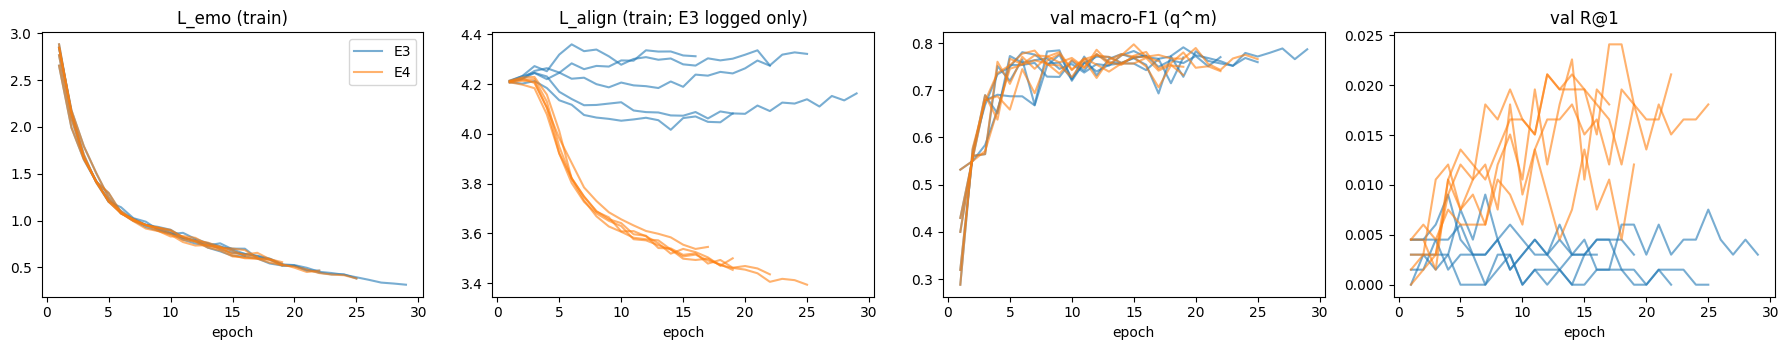

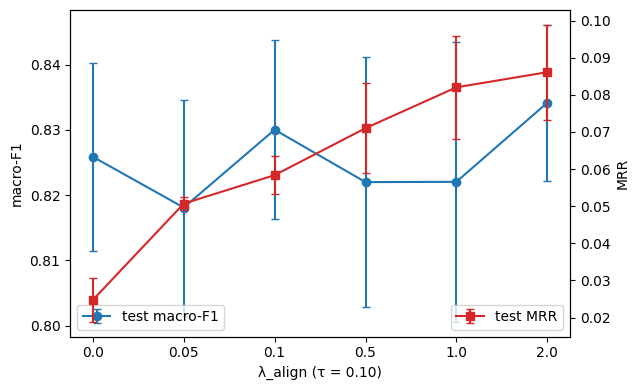

In [59]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for exp, c in (("E3", "tab:blue"), ("E4", "tab:orange")):
    for sd in FINAL_SEEDS:
        h = pd.read_csv(f"{OUT3}/hist_{exp}_s{sd}.csv")
        for a, m in zip(ax, ("L_emo", "L_align", "val_f1", "val_R1")):
            a.plot(h.epoch, h[m], color=c, alpha=0.6, label=exp if sd == 0 else None)
for a, t in zip(ax, ("L_emo (train)", "L_align (train; E3 logged only)", "val macro-F1 (q^m)", "val R@1")):
    a.set_title(t); a.set_xlabel("epoch")
ax[0].legend(); plt.tight_layout(); plt.savefig(f"{OUT5}/training_curves.png", dpi=150); plt.show()

g = S5.groupby("lam_align"); mu, sd_ = g.mean(numeric_only=True), g.std(numeric_only=True); x = np.arange(len(mu))
fig, a1 = plt.subplots(figsize=(6.5, 4))
a1.errorbar(x, mu.test_f1, sd_.test_f1, marker="o", capsize=3, label="test macro-F1")
a1.set_xticks(x, [str(v) for v in mu.index]); a1.set_xlabel("λ_align (τ = %.2f)" % TAU4); a1.set_ylabel("macro-F1")
a2 = a1.twinx(); a2.errorbar(x, mu.test_MRR, sd_.test_MRR, marker="s", color="tab:red", capsize=3, label="test MRR")
a2.set_ylabel("MRR"); a1.legend(loc="lower left"); a2.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT5}/lambda_sweep.png", dpi=150); plt.show()

In [60]:
import shutil
for d in ("p4", "p5"):
    shutil.make_archive(f"/kaggle/working/{d}_outputs", "zip", f"/kaggle/working/{d}")